In [2]:
import pandas as pd
import numpy as np
import itertools
from scipy.stats import norm
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from scipy.optimize import minimize


## Data formating

In [3]:
file_path = r"C:\Users\ulsi\Trend_data.xlsx"

# Load full dataset
df_total = pd.read_excel(file_path)



# Replicate the paper's universe: drop column C (index 2) and column M (index 12)
df_original = df_total.drop(df_total.columns[[2, 12]], axis=1)


for df in (df_total, df_original):
    df["DATES"] = pd.to_datetime(df["DATES"])
    df.set_index("DATES", inplace=True)

df_total_diff = df_total.pct_change().dropna()
df_original_diff = df_original.pct_change().dropna()

split_idx = int(len(df_original_diff) * 0.8)

df_original_diff_train = df_original_diff.iloc[:split_idx]
df_original_diff_test  = df_original_diff.iloc[split_idx:]

df_total_diff_train = df_total_diff.iloc[:split_idx]
df_total_diff_test  = df_total_diff.iloc[split_idx:]



## Functions

In [4]:
"""
Sparse Group Lasso replication pipeline for the SG Trend Index (NEIXTRND).
Sections:
  1. Asset universe & classes
  2. Trend measure (Tzotchev)
  3. Strategy generation (risk-parity trend systems)
  4. Strategy universe builder (the (M,T,N,assets) grid -> design matrix)
  5. Non-negative Sparse Group Lasso solver (proximal gradient, Nesterov)
  6. Regularization path & cross-validation utilities
"""

import itertools
import time
import numpy as np
import pandas as pd
from scipy.stats import norm


# ============================================================================
# 1. Asset universe & classes (Table 1 of the paper)
#    NOTE: this is the df_original_diff (10-asset) version. For df_total_diff
#    (12 assets), add "VG1 Index": "Equities" and "RX1 Comdty": "FixedIncome".
# ============================================================================



ASSET_CLASS_MAP_10 = {
    "ES1 Index":      "Equities",
          
    "SB1 Comdty":     "Commodities",
    "HG1 Comdty":     "Commodities",
    "GC1 Comdty":     "Commodities",
    "C 1 Comdty":     "Commodities",
    "CL1 Comdty":     "Energy",
    "TY1 Comdty":     "FixedIncome",
       
    "GBPUSD Curncy":  "FX",
    "EURUSD Curncy":  "FX",
    "USDJPY Curncy":  "FX",
}
ASSETS_10 = list(ASSET_CLASS_MAP_10.keys())

ASSET_CLASS_MAP_12 = {
    "ES1 Index":      "Equities",
    "VG1 Index":      "Equities",      
    "SB1 Comdty":     "Commodities",
    "HG1 Comdty":     "Commodities",
    "GC1 Comdty":     "Commodities",
    "C 1 Comdty":     "Commodities",
    "CL1 Comdty":     "Energy",
    "TY1 Comdty":     "FixedIncome",
    "RX1 Comdty":     "FixedIncome",   
    "GBPUSD Curncy":  "FX",
    "EURUSD Curncy":  "FX",
    "USDJPY Curncy":  "FX",
}
ASSETS_12 = list(ASSET_CLASS_MAP_12.keys())
DAILY_VOL_TARGET = 0.15 / np.sqrt(252)  # 15% annualized -> daily


# ============================================================================
# 2. Trend measure (Tzotchev et al., 2015)
#    S_T = 2*Phi(sqrt(T) * r_bar_T / sigma_hat_T) - 1
# ============================================================================
def tzotchev_trend_measure(returns: pd.DataFrame, T: int) -> pd.Series:
    """One trend measure S_T per asset (column), over the whole `returns` sample passed in."""
    r_bar = returns.mean()
    sigma_hat = returns.std()
    z = np.sqrt(T) * r_bar / sigma_hat
    return pd.Series(2 * norm.cdf(z) - 1, index=returns.columns)


def precompute_rolling_stats(returns: pd.DataFrame, T_grid) -> dict:
    """One rolling mean/std per T, computed once for the whole asset universe."""
    return {
        T: {"mean": returns.rolling(T).mean(), "std": returns.rolling(T).std()}
        for T in T_grid
    }


# ============================================================================
# 3. Strategy generation — now takes asset_class_map explicitly
# ============================================================================
def generate_trend_strategy(returns: pd.DataFrame, assets_subset: list,
                             T: int, N: int, precomputed: dict,
                             asset_class_map: dict,
                             target_vol: float = DAILY_VOL_TARGET) -> pd.Series:
    idx = returns.index
    n_obs = len(idx)
    strat_ret = np.zeros(n_obs)

    mean_T = precomputed[T]["mean"][list(assets_subset)].values
    std_T = precomputed[T]["std"][list(assets_subset)].values
    ret_vals = returns[list(assets_subset)].values

    classes = [asset_class_map[a] for a in assets_subset]
    unique_classes = list(set(classes))
    K = len(unique_classes)
    class_budget = target_vol / np.sqrt(K)
    class_to_indices = {
        c: [i for i, cc in enumerate(classes) if cc == c] for c in unique_classes
    }

    for start in range(T, n_obs, N):
        row = start - 1
        m, s = mean_T[row], std_T[row]
        signs = np.where(m >= 0, 1.0, -1.0)

        weights = np.zeros(len(assets_subset))
        for c, idxs in class_to_indices.items():
            per_asset_budget = class_budget / len(idxs)
            weights[idxs] = per_asset_budget / s[idxs]

        positions = signs * weights
        end = min(start + N, n_obs)
        strat_ret[start:end] = ret_vals[start:end] @ positions

    return pd.Series(strat_ret, index=idx)

def generate_trend_strategy_costed(returns: pd.DataFrame, assets_subset: list,
                                    T: int, N: int, precomputed: dict,
                                    asset_class_map: dict,
                                    target_vol: float = DAILY_VOL_TARGET,
                                    cost_bps: float = 0.0002) -> dict:
    """
    Same logic as generate_trend_strategy, but also tracks position changes
    at each rebalance to compute transaction costs (paper's 2bps convention).

    Returns a dict with:
      gross_returns : pd.Series, return series before costs
      net_returns   : pd.Series, return series after costs
      turnover      : pd.Series, turnover at each rebalance date (0 elsewhere)
    """
    idx = returns.index
    n_obs = len(idx)
    gross_ret = np.zeros(n_obs)
    net_ret = np.zeros(n_obs)
    turnover_track = np.zeros(n_obs)

    mean_T = precomputed[T]["mean"][list(assets_subset)].values
    std_T = precomputed[T]["std"][list(assets_subset)].values
    ret_vals = returns[list(assets_subset)].values

    classes = [asset_class_map[a] for a in assets_subset]
    unique_classes = list(set(classes))
    K = len(unique_classes)
    class_budget = target_vol / np.sqrt(K)
    class_to_indices = {
        c: [i for i, cc in enumerate(classes) if cc == c] for c in unique_classes
    }

    prev_positions = np.zeros(len(assets_subset))  # start fully flat (first rebalance = entering from 0)

    for start in range(T, n_obs, N):
        row = start - 1
        m, s = mean_T[row], std_T[row]
        signs = np.where(m >= 0, 1.0, -1.0)

        weights = np.zeros(len(assets_subset))
        for c, idxs in class_to_indices.items():
            per_asset_budget = class_budget / len(idxs)
            weights[idxs] = per_asset_budget / s[idxs]

        positions = signs * weights

        turnover = np.sum(np.abs(positions - prev_positions))
        cost = turnover * cost_bps
        turnover_track[start] = turnover

        end = min(start + N, n_obs)
        period_returns = ret_vals[start:end] @ positions
        gross_ret[start:end] = period_returns
        net_ret[start:end] = period_returns
        net_ret[start] -= cost  # cost hits on the rebalance day itself

        prev_positions = positions

    return {
        "gross_returns": pd.Series(gross_ret, index=idx),
        "net_returns": pd.Series(net_ret, index=idx),
        "turnover": pd.Series(turnover_track, index=idx),
    }

def sample_asset_subsets(M: int, n_subsets: int, universe: list,
                          rng: np.random.Generator) -> list:
    """Up to n_subsets distinct M-sized subsets of `universe` (uses all C(len(universe),M) if fewer)."""
    all_combos = list(itertools.combinations(universe, M))
    if len(all_combos) <= n_subsets:
        return all_combos
    idx = rng.choice(len(all_combos), size=n_subsets, replace=False)
    return [all_combos[i] for i in idx]


# ============================================================================
# 4. Strategy universe builder — now takes asset_class_map / universe explicitly
# ============================================================================
def build_strategy_universe(returns: pd.DataFrame,
                             asset_class_map: dict,
                             universe: list,
                             T_grid=(21, 63, 126, 252),
                             N_grid=(10, 25),
                             M_grid=(3, 6, 9),
                             n_subsets_per_M: int = 30,
                             seed: int = 42):
    """Builds the (M,T,N,assets) design matrix X and its metadata (incl. SGL group = M)."""
    rng = np.random.default_rng(seed)
    precomputed = precompute_rolling_stats(returns, T_grid)

    strategies, meta = {}, []
    for M in M_grid:
        subsets = sample_asset_subsets(M, n_subsets_per_M, universe, rng)
        for assets_subset in subsets:
            for T in T_grid:
                for N in N_grid:
                    col_name = f"M{M}_T{T}_N{N}_{'-'.join(assets_subset)}"
                    strategies[col_name] = generate_trend_strategy(
                        returns, assets_subset, T, N, precomputed, asset_class_map
                    )
                    meta.append({"strategy": col_name, "M": M, "T": T, "N": N,
                                 "assets": assets_subset, "group": M})

    X = pd.DataFrame(strategies)
    meta_df = pd.DataFrame(meta).set_index("strategy")
    return X, meta_df

def build_strategy_universe_costed(returns: pd.DataFrame,
                                    asset_class_map: dict, universe: list,
                                    T_grid=(21, 63, 126, 252), N_grid=(10, 25),
                                    M_grid=(3, 6, 9), n_subsets_per_M: int = 30,
                                    seed: int = 42, cost_bps: float = 0.0002):
    rng = np.random.default_rng(seed)
    precomputed = precompute_rolling_stats(returns, T_grid)

    gross, net, turnover, meta = {}, {}, {}, []
    for M in M_grid:
        subsets = sample_asset_subsets(M, n_subsets_per_M, universe, rng)
        for assets_subset in subsets:
            for T in T_grid:
                for N in N_grid:
                    col_name = f"M{M}_T{T}_N{N}_{'-'.join(assets_subset)}"
                    result = generate_trend_strategy_costed(
                        returns, assets_subset, T, N, precomputed,
                        asset_class_map, cost_bps=cost_bps
                    )
                    gross[col_name] = result["gross_returns"]
                    net[col_name] = result["net_returns"]
                    turnover[col_name] = result["turnover"]
                    meta.append({"strategy": col_name, "M": M, "T": T, "N": N,
                                 "assets": assets_subset, "group": M})

    X_gross = pd.DataFrame(gross)
    X_net = pd.DataFrame(net)
    X_turnover = pd.DataFrame(turnover)
    meta_df = pd.DataFrame(meta).set_index("strategy")
    return X_gross, X_net, X_turnover, meta_df





# ============================================================================
# 9. Univariate (single-strategy) fit diagnostics
# ============================================================================
def univariate_strategy_r2(X: pd.DataFrame, y: np.ndarray, meta: pd.DataFrame,
                            top_n: int = 10) -> pd.DataFrame:
    """
    For each strategy independently, fits a no-intercept OLS slope against y
    (b = x.y / x.x) and reports its standalone R² — i.e. "how well does this
    ONE strategy, on its own, replicate the target?" Returns the top_n by R².
    """
    X_vals = X.values

    b = (X_vals * y[:, None]).sum(axis=0) / (X_vals ** 2).sum(axis=0)
    pred = X_vals * b

    ss_res = ((y[:, None] - pred) ** 2).sum(axis=0)
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot

    stats = pd.DataFrame({"r2": r2, "slope": b}, index=X.columns).join(
        meta[["M", "T", "N", "assets"]]
    )
    return stats.sort_values("r2", ascending=False).head(top_n)


from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score
from scipy.optimize import nnls

# ============================================================================
# 10. Unsupervised-first pipeline: cluster on correlation (target-blind),
#     pick representative medoids, THEN regress on the reduced set.
# ============================================================================

def _build_distance_matrix(X_subset: pd.DataFrame) -> np.ndarray:
    """1 - |correlation| distance matrix among a set of strategies."""
    corr = X_subset.corr().values
    dist = 1 - np.abs(corr)
    np.fill_diagonal(dist, 0)
    dist = (dist + dist.T) / 2  # enforce exact symmetry (float rounding safety)
    return dist


def _select_k_by_silhouette(dist: np.ndarray, Z: np.ndarray, k_grid) -> tuple:
    """Scans k_grid, returns (best_k, best_score, scores_dict) using silhouette
    on the precomputed correlation-distance matrix. Target-blind by construction."""
    scores = {}
    for k in k_grid:
        if k < 2 or k >= dist.shape[0]:
            continue
        labels = fcluster(Z, t=k, criterion="maxclust")
        if len(np.unique(labels)) < 2:  # silhouette needs >=2 clusters
            continue
        score = silhouette_score(dist, labels, metric="precomputed")
        scores[k] = score

    if not scores:
        return None, None, scores
    best_k = max(scores, key=scores.get)
    return best_k, scores[best_k], scores


def _medoids_for_labels(dist: np.ndarray, labels: np.ndarray, col_names: list) -> list:
    """For each cluster, returns the strategy with the smallest average
    distance to all other members of its own cluster (the medoid)."""
    reps = []
    for c in np.unique(labels):
        members = np.where(labels == c)[0]
        if len(members) == 1:
            reps.append(col_names[members[0]])
            continue
        sub_dist = dist[np.ix_(members, members)]
        avg_dist = sub_dist.mean(axis=1)
        medoid_local = members[np.argmin(avg_dist)]
        reps.append(col_names[medoid_local])
    return reps


def cluster_and_select_medoids(X: pd.DataFrame, meta: pd.DataFrame,
                                per_group: bool = True,
                                k_grid=range(2, 31),
                                linkage_method: str = "average",
                                verbose: bool = True) -> pd.DataFrame:
    """
    Stage 1 (unsupervised, target-blind): hierarchical clustering on
    correlation distance, cluster count chosen via silhouette score,
    medoid representative kept per cluster.

    per_group=True: clusters WITHIN each M separately (preserves M as a
        clean group label for stage 2). Recommended given our SGL setup.
    per_group=False: clusters across the WHOLE universe at once (clusters
        may mix different M values together).

    Returns a DataFrame of chosen representatives with their cluster info.
    """
    results = []

    groups_to_process = meta["M"].unique() if per_group else [None]

    for m_val in groups_to_process:
        if per_group:
            cols = meta[meta["M"] == m_val].index.tolist()
        else:
            cols = meta.index.tolist()

        X_subset = X[cols]
        dist = _build_distance_matrix(X_subset)
        condensed = squareform(dist, checks=False)
        Z = linkage(condensed, method=linkage_method)

        best_k, best_score, scores = _select_k_by_silhouette(dist, Z, k_grid)
        if best_k is None:
            if verbose:
                print(f"  M={m_val}: too few strategies to cluster meaningfully, keeping all {len(cols)}")
            reps = cols
            best_k = len(cols)
            best_score = np.nan
        else:
            labels = fcluster(Z, t=best_k, criterion="maxclust")
            reps = _medoids_for_labels(dist, labels, cols)

        if verbose:
            tag = f"M={m_val}" if per_group else "ALL"
            print(f"  {tag}: {len(cols)} strategies -> best_k={best_k} "
                  f"(silhouette={best_score:.4f})" if not np.isnan(best_score)
                  else f"  {tag}: {len(cols)} strategies -> kept all (no clustering)")

        for rep in reps:
            results.append({"representative": rep, "source_M": m_val, "n_clusters_in_group": best_k})

    return pd.DataFrame(results).set_index("representative")


# ============================================================================
# Stage 2: supervised regression on the reduced, decorrelated feature set
# ============================================================================
def refit_nnls(X: pd.DataFrame, y: np.ndarray, selected_cols: list) -> tuple:
    """Non-negative least squares on the reduced set (collinearity mostly
    resolved by clustering, so a full SGL penalty may not be necessary)."""
    X_sel = X[selected_cols].values
    beta, _ = nnls(X_sel, y)
    fitted = X_sel @ beta
    r2 = 1 - np.sum((y - fitted) ** 2) / np.sum((y - y.mean()) ** 2)
    return beta, r2


# ============================================================================
# 10. Unsupervised-first pipeline: cluster on correlation (target-blind),
#     pick representative medoids, THEN regress on the reduced set.
# ============================================================================
def _build_distance_matrix(X_subset: pd.DataFrame) -> np.ndarray:
    """1 - |correlation| distance matrix among a set of strategies."""
    corr = X_subset.corr().values
    dist = 1 - np.abs(corr)
    np.fill_diagonal(dist, 0)
    dist = (dist + dist.T) / 2  # enforce exact symmetry (float rounding safety)
    return dist


def _select_k_by_silhouette(dist: np.ndarray, Z: np.ndarray, k_grid) -> tuple:
    """Scans k_grid, returns (best_k, best_score, scores_dict) using silhouette
    on the precomputed correlation-distance matrix. Target-blind by construction."""
    scores = {}
    for k in k_grid:
        if k < 2 or k >= dist.shape[0]:
            continue
        labels = fcluster(Z, t=k, criterion="maxclust")
        if len(np.unique(labels)) < 2:
            continue
        scores[k] = silhouette_score(dist, labels, metric="precomputed")

    if not scores:
        return None, None, scores
    best_k = max(scores, key=scores.get)
    return best_k, scores[best_k], scores


def _medoids_for_labels(dist: np.ndarray, labels: np.ndarray, col_names: list) -> list:
    """For each cluster, returns the strategy with the smallest average
    distance to all other members of its own cluster (the medoid)."""
    reps = []
    for c in np.unique(labels):
        members = np.where(labels == c)[0]
        if len(members) == 1:
            reps.append(col_names[members[0]])
            continue
        sub_dist = dist[np.ix_(members, members)]
        avg_dist = sub_dist.mean(axis=1)
        reps.append(col_names[members[np.argmin(avg_dist)]])
    return reps


def cluster_and_select_medoids(X: pd.DataFrame, meta: pd.DataFrame,
                                per_group: bool = True,
                                k_grid=range(2, 31),
                                linkage_method: str = "average",
                                verbose: bool = True) -> pd.DataFrame:
    """
    Stage 1 (unsupervised, target-blind): hierarchical clustering on
    correlation distance, cluster count chosen via silhouette score,
    medoid representative kept per cluster.

    per_group=True: clusters WITHIN each M separately (preserves M as a
        clean group label). Recommended given our SGL group structure.
    """
    results = []
    groups_to_process = meta["M"].unique() if per_group else [None]

    for m_val in groups_to_process:
        cols = meta[meta["M"] == m_val].index.tolist() if per_group else meta.index.tolist()

        X_subset = X[cols]
        dist = _build_distance_matrix(X_subset)
        condensed = squareform(dist, checks=False)
        Z = linkage(condensed, method=linkage_method)

        best_k, best_score, _ = _select_k_by_silhouette(dist, Z, k_grid)
        if best_k is None:
            if verbose:
                print(f"  M={m_val}: too few strategies to cluster meaningfully, keeping all {len(cols)}")
            reps = cols
        else:
            labels = fcluster(Z, t=best_k, criterion="maxclust")
            reps = _medoids_for_labels(dist, labels, cols)
            if verbose:
                print(f"  M={m_val}: {len(cols)} strategies -> best_k={best_k} (silhouette={best_score:.4f})")

        for rep in reps:
            results.append({"representative": rep, "source_M": m_val})

    return pd.DataFrame(results).set_index("representative")


def refit_nnls(X: pd.DataFrame, y: np.ndarray, selected_cols: list) -> tuple:
    """Non-negative least squares on the reduced set (collinearity mostly
    resolved by clustering, so a full SGL penalty isn't necessary here)."""
    X_sel = X[selected_cols].values
    beta, _ = nnls(X_sel, y)
    fitted = X_sel @ beta
    r2 = 1 - np.sum((y - fitted) ** 2) / np.sum((y - y.mean()) ** 2)
    return beta, r2


# ============================================================================
# 11. Redundancy check & merge (catches any cross-M collinearity clustering
#     missed, since clustering was done WITHIN each M separately)
# ============================================================================
def find_high_corr_pairs(X: pd.DataFrame, cols: list, threshold: float = 0.85) -> list:
    """Returns (col_a, col_b, corr) for every pair among `cols` exceeding threshold."""
    corr_vals = X[cols].corr().abs().to_numpy(copy=True)
    np.fill_diagonal(corr_vals, 0)
    n = len(cols)
    pairs = [(cols[i], cols[j], corr_vals[i, j])
             for i in range(n) for j in range(i + 1, n)
             if corr_vals[i, j] > threshold]
    return sorted(pairs, key=lambda x: -x[2])


def merge_redundant_pairs(X: pd.DataFrame, y: np.ndarray, selected_cols: list,
                           weights: np.ndarray, threshold: float = 0.85,
                           verbose: bool = True) -> tuple:
    """
    Finds pairs above `threshold` correlation and drops the lower-weighted
    member of each, then refits NNLS on the survivors. Repeats once (a
    single pass is normally enough given how few pairs tend to survive
    clustering) rather than iterating to convergence.
    """
    pairs = find_high_corr_pairs(X, selected_cols, threshold)
    weight_map = dict(zip(selected_cols, weights))

    to_drop = set()
    for a, b, c in pairs:
        if a in to_drop or b in to_drop:
            continue
        drop = a if weight_map[a] < weight_map[b] else b
        to_drop.add(drop)
        if verbose:
            print(f"  dropping {drop} (corr={c:.3f} with its pair)")

    remaining = [c for c in selected_cols if c not in to_drop]
    beta, r2 = refit_nnls(X, y, remaining)
    return beta, r2, remaining


def merge_redundant_pairs(X: pd.DataFrame, y: np.ndarray, selected_cols: list,
                           weights: np.ndarray, threshold: float = 0.85,
                           verbose: bool = True) -> tuple:
    """
    Finds pairs above `threshold` correlation AMONG ACTIVE (non-zero weight)
    strategies only, drops the lower-weighted member of each pair, then
    refits NNLS on the survivors.
    """
    # Only consider strategies NNLS actually kept
    active_mask = weights != 0
    active_cols = [c for c, m in zip(selected_cols, active_mask) if m]
    active_weights = weights[active_mask]

    pairs = find_high_corr_pairs(X, active_cols, threshold)
    weight_map = dict(zip(active_cols, active_weights))

    to_drop = set()
    for a, b, c in pairs:
        if a in to_drop or b in to_drop:
            continue
        drop = a if weight_map[a] < weight_map[b] else b
        to_drop.add(drop)
        if verbose:
            print(f"  dropping {drop} (corr={c:.3f} with its pair)")

    remaining = [c for c in active_cols if c not in to_drop]  # only from the active set
    beta, r2 = refit_nnls(X, y, remaining)
    return beta, r2, remaining

def refit_nonneg_lasso(X: pd.DataFrame, y: np.ndarray, selected_cols: list,
                        n_splits: int = 5) -> tuple:
    """
    Non-negative Lasso (via sklearn's positive=True) on the reduced,
    already-decorrelated set of strategies. CV-selects alpha using
    expanding-window time-series splits.
    """
    X_sel = X[selected_cols].values
    tscv = TimeSeriesSplit(n_splits=n_splits)

    model = LassoCV(positive=True, fit_intercept=False, cv=tscv,
                     alphas=100, max_iter=10000)  # alphas=100 replaces n_alphas=100
    model.fit(X_sel, y)

    beta = model.coef_
    fitted = X_sel @ beta
    r2 = 1 - np.sum((y - fitted) ** 2) / np.sum((y - y.mean()) ** 2)

    return beta, r2, model.alpha_



def refit_ridge_by_oos_r2(X_train_sel: np.ndarray, y_train: np.ndarray,
                           X_test_sel: np.ndarray, y_test: np.ndarray,
                           alpha_grid: np.ndarray, positive: bool = True) -> dict:
    """
    Fits Ridge at each alpha in alpha_grid on TRAINING data, then picks
    whichever alpha gives the HIGHEST R² on the TEST set.
    WARNING: this tunes the hyperparameter using the test set itself —
    it is data snooping, not a fair estimate of generalization. Use only
    as an exploratory upper-bound diagnostic.
    """
    results = []
    for alpha in alpha_grid:
        model = Ridge(alpha=alpha, fit_intercept=False, positive=positive,
                      solver="lbfgs" if positive else "auto")
        model.fit(X_train_sel, y_train)

        fitted_train = X_train_sel @ model.coef_
        r2_train = 1 - np.sum((y_train - fitted_train)**2) / np.sum((y_train - y_train.mean())**2)

        fitted_test = X_test_sel @ model.coef_
        r2_test = 1 - np.sum((y_test - fitted_test)**2) / np.sum((y_test - y_test.mean())**2)

        results.append({"alpha": alpha, "r2_train": r2_train, "r2_test": r2_test, "coef": model.coef_})

    results_df = pd.DataFrame(results)
    best_row = results_df.loc[results_df["r2_test"].idxmax()]
    return {"results_df": results_df, "best_alpha": best_row["alpha"],
            "best_r2_test": best_row["r2_test"], "best_coef": best_row["coef"]}


def refit_ridge_by_cv(X_train_sel: np.ndarray, y_train: np.ndarray,
                       alpha_grid: np.ndarray, n_splits: int = 5,
                       positive: bool = True):
    """
    Proper, honest alpha selection: cross-validated on TRAINING data only,
    using expanding time-series splits. Test set is never touched here.
    """
    # RidgeCV doesn't support positive=True directly, so do it manually
    tscv = TimeSeriesSplit(n_splits=n_splits)
    cv_scores = {alpha: [] for alpha in alpha_grid}

    for train_idx, val_idx in tscv.split(X_train_sel):
        for alpha in alpha_grid:
            model = Ridge(alpha=alpha, fit_intercept=False, positive=positive,
                          solver="lbfgs" if positive else "auto")
            model.fit(X_train_sel[train_idx], y_train[train_idx])
            fitted_val = X_train_sel[val_idx] @ model.coef_
            r2_val = 1 - np.sum((y_train[val_idx] - fitted_val)**2) / np.sum((y_train[val_idx] - y_train[val_idx].mean())**2)
            cv_scores[alpha].append(r2_val)

    mean_scores = {alpha: np.mean(v) for alpha, v in cv_scores.items()}
    best_alpha = max(mean_scores, key=mean_scores.get)

    model = Ridge(alpha=best_alpha, fit_intercept=False, positive=positive,
                  solver="lbfgs" if positive else "auto")
    model.fit(X_train_sel, y_train)
    return {"best_alpha": best_alpha, "coef": model.coef_, "cv_scores": mean_scores}



def portfolio_net_returns_and_turnover(X_net: pd.DataFrame, X_turnover: pd.DataFrame,
                                        active_cols: list, weights: np.ndarray) -> dict:
    net_portfolio = (X_net[active_cols].values * weights).sum(axis=1)
    net_portfolio_series = pd.Series(net_portfolio, index=X_net.index)

    # Weighted turnover, summed across strategies (see netting caveat above)
    weighted_turnover = (X_turnover[active_cols].values * np.abs(weights)).sum(axis=1)
    avg_daily_turnover_pct = weighted_turnover.sum() / len(X_turnover) * 100

    return {"net_returns": net_portfolio_series, "avg_daily_turnover_pct": avg_daily_turnover_pct}

def rolling_lasso_holding_period(returns: pd.DataFrame, asset_cols: list, target_col: str,
                                  window: int = 21, N: int = 10, cv_splits: int = 3) -> tuple:
    """
    Refits Lasso every N days on a trailing `window`-day sample, holds those
    weights for the following N-day period (no lookahead: uses only data
    strictly before the holding period to fit).
    """
    dates = returns.index
    n_obs = len(dates)
    predictions = np.zeros(n_obs)
    weights_over_time = {}

    for start in range(window, n_obs - N, N):
        X_window = returns[asset_cols].iloc[start-window:start].values
        y_window = returns[target_col].iloc[start-window:start].values

        n_splits = max(min(cv_splits, window // 5), 2)
        tscv = TimeSeriesSplit(n_splits=n_splits)
        model = LassoCV(cv=tscv, fit_intercept=False, alphas=20, max_iter=20000, tol=1e-6)
        model.fit(X_window, y_window)
        weights_over_time[dates[start]] = model.coef_

        end = min(start + N, n_obs)
        X_holding = returns[asset_cols].iloc[start:end].values
        predictions[start:end] = X_holding @ model.coef_

    pred_series = pd.Series(predictions, index=dates)
    weights_df = pd.DataFrame(weights_over_time, index=asset_cols).T
    return weights_df, pred_series

from sklearn.linear_model import ElasticNetCV

def rolling_elasticnet_with_turnover(returns: pd.DataFrame, asset_cols: list, target_col: str,
                                      window: int, N: int, cost_bps: float = 0.0002,
                                      l1_ratio_grid=(.1, .3, .5, .7, .9, .95, 1.0)) -> dict:
    """Same rolling scheme as rolling_lasso_with_turnover, but ElasticNet at each refit."""
    dates = returns.index
    n_obs = len(dates)
    gross_returns = np.zeros(n_obs)
    net_returns = np.zeros(n_obs)
    turnover = np.zeros(n_obs)
    prev_weights = np.zeros(len(asset_cols))

    for start in range(window, n_obs - N, N):
        X_window = returns[asset_cols].iloc[start-window:start].values
        y_window = returns[target_col].iloc[start-window:start].values

        n_splits = max(min(3, window // 5), 2)
        tscv = TimeSeriesSplit(n_splits=n_splits)
        model = ElasticNetCV(cv=tscv, l1_ratio=list(l1_ratio_grid),
                              fit_intercept=False, alphas=20, max_iter=20000, tol=1e-6)
        model.fit(X_window, y_window)
        new_weights = model.coef_

        trade_size = np.abs(new_weights - prev_weights).sum()
        cost = trade_size * cost_bps

        end = min(start + N, n_obs)
        X_holding = returns[asset_cols].iloc[start:end].values
        period_returns = X_holding @ new_weights
        gross_returns[start:end] = period_returns
        net_returns[start:end] = period_returns
        net_returns[start] -= cost
        turnover[start] = trade_size

        prev_weights = new_weights

    return {
        "gross": pd.Series(gross_returns, index=dates),
        "net": pd.Series(net_returns, index=dates),
        "turnover": pd.Series(turnover, index=dates),
    }

def cv_select_window_and_N(returns: pd.DataFrame, asset_cols: list, target_col: str,
                            window_grid: list, N_grid: list,
                            cv_splits: int = 3) -> pd.DataFrame:
    """
    Grid search over (window, N) for the rolling Lasso, evaluated via
    expanding-window walk-forward R² WITHIN the training period only.
    """
    results = []
    for window in window_grid:
        for N in N_grid:
            _, preds = rolling_lasso_holding_period(returns, asset_cols, target_col,
                                                      window=window, N=N, cv_splits=cv_splits)
            valid_mask = preds != 0
            y_valid = returns.loc[valid_mask, target_col]
            preds_valid = preds[valid_mask]

            ss_res = np.sum((y_valid - preds_valid) ** 2)
            ss_tot = np.sum((y_valid - y_valid.mean()) ** 2)
            r2 = 1 - ss_res / ss_tot

            results.append({"window": window, "N": N, "walkforward_r2": r2})
            print(f"  window={window}, N={N}: R²={r2:.4f}")

    return pd.DataFrame(results).sort_values("walkforward_r2", ascending=False)

def rolling_lasso_with_turnover(returns: pd.DataFrame, asset_cols: list, target_col: str,
                                  window: int, N: int, cost_bps: float = 0.0002) -> dict:
    """Same rolling Lasso scheme, but also tracks turnover and net-of-cost returns."""
    dates = returns.index
    n_obs = len(dates)
    gross_returns = np.zeros(n_obs)
    net_returns = np.zeros(n_obs)
    turnover = np.zeros(n_obs)
    prev_weights = np.zeros(len(asset_cols))

    for start in range(window, n_obs - N, N):
        X_window = returns[asset_cols].iloc[start-window:start].values
        y_window = returns[target_col].iloc[start-window:start].values

        tscv = TimeSeriesSplit(n_splits=max(min(3, window // 5), 2))
        model = LassoCV(cv=tscv, fit_intercept=False, alphas=20, max_iter=20000, tol=1e-6)
        model.fit(X_window, y_window)
        new_weights = model.coef_

        trade_size = np.abs(new_weights - prev_weights).sum()
        cost = trade_size * cost_bps

        end = min(start + N, n_obs)
        X_holding = returns[asset_cols].iloc[start:end].values
        period_returns = X_holding @ new_weights
        gross_returns[start:end] = period_returns
        net_returns[start:end] = period_returns
        net_returns[start] -= cost  # cost hits on the rebalance day
        turnover[start] = trade_size

        prev_weights = new_weights

    return {
        "gross": pd.Series(gross_returns, index=dates),
        "net": pd.Series(net_returns, index=dates),
        "turnover": pd.Series(turnover, index=dates),
    }







def winsorize_returns_train_stats(df_apply: pd.DataFrame, df_stats_source: pd.DataFrame,
                                   n_std: float = 5.0) -> pd.DataFrame:
    """Winsorizes df_apply using mean/std computed from df_stats_source (e.g. training data),
    avoiding any lookahead when applied to a test set."""
    df_wins = df_apply.copy()
    for col in df_apply.columns:
        std = df_stats_source[col].std()
        mean = df_stats_source[col].mean()
        df_wins[col] = df_apply[col].clip(mean - n_std*std, mean + n_std*std)
    return df_wins

## Plotting and table functions

In [5]:
def plot_dendrogram_with_cutoff(X: pd.DataFrame, meta: pd.DataFrame, m_val: int,
                                 k_grid=range(2, 31), linkage_method: str = "average"):
    """Rebuilds the linkage tree for one M group, finds its silhouette-selected
    k (same logic as cluster_and_select_medoids), and plots the dendrogram
    with a horizontal line marking where that cut happens."""
    cols = meta[meta["M"] == m_val].index.tolist()
    X_subset = X[cols]

    dist = _build_distance_matrix(X_subset)
    condensed = squareform(dist, checks=False)
    Z = linkage(condensed, method=linkage_method)

    best_k, best_score, scores = _select_k_by_silhouette(dist, Z, k_grid)

    # Height at which cutting the tree yields exactly best_k clusters
    heights = np.sort(Z[:, 2])
    m = len(heights)
    if best_k < m + 1:
        cutoff = (heights[m - best_k] + heights[m - best_k + 1]) / 2 if best_k > 1 else heights[-1] + 0.01
    else:
        cutoff = heights[-1] + 0.01

    fig, ax = plt.subplots(dpi=200, figsize=(7, 3))
    dendrogram(Z, ax=ax, color_threshold=cutoff, no_labels=True)
    ax.axhline(cutoff, color='red', lw=1.2, linestyle='--',
               label=f"Cutoff -> {best_k} clusters")

    ax.set_xlabel("Strategies", fontsize=8)
    ax.set_ylabel("Distance (1 - |correlation|)", fontsize=8)
    ax.tick_params(labelsize=6)
    ax.legend(fontsize=6)
    ax.set_title(f"Hierarchical clustering, M={m_val} (silhouette={best_score:.3f})", fontsize=9)

    plt.tight_layout()
    plt.show()

    return Z, best_k, scores

def plot_dendrogram_and_silhouette(X: pd.DataFrame, meta: pd.DataFrame, m_val: int,
                                    k_grid=range(2, 31), linkage_method: str = "average"):
    """Side-by-side dendrogram (left) + silhouette-vs-k curve (right) for one M group."""
    cols = meta[meta["M"] == m_val].index.tolist()
    X_subset = X[cols]

    dist = _build_distance_matrix(X_subset)
    condensed = squareform(dist, checks=False)
    Z = linkage(condensed, method=linkage_method)

    best_k, best_score, scores = _select_k_by_silhouette(dist, Z, k_grid)

    heights = np.sort(Z[:, 2])
    m = len(heights)
    if best_k < m + 1:
        cutoff = (heights[m - best_k] + heights[m - best_k + 1]) / 2 if best_k > 1 else heights[-1] + 0.01
    else:
        cutoff = heights[-1] + 0.01

    fig, axes = plt.subplots(1, 2, dpi=200, figsize=(8, 3))

    ax = axes[0]
    dendrogram(Z, ax=ax, color_threshold=cutoff, no_labels=True)
    ax.set_xlabel("Strategies", fontsize=8); ax.set_ylabel(r"Distance (1 - $|\rho|$)", fontsize=8)
    ax.tick_params(labelsize=6)
    ax.set_title(f"Dendrogram, M={m_val}", fontsize=9)

    ax = axes[1]
    ks = sorted(scores.keys())
    vals = [scores[k] for k in ks]
    ax.plot(ks, vals, color='black', lw=1.2, marker='o', markersize=3)
    ax.set_xlabel("Number of clusters (k)", fontsize=8); ax.set_ylabel("Silhouette score", fontsize=8)
    ax.tick_params(labelsize=6)
    ax.set_title(f"Silhouette score vs. k, M={m_val}", fontsize=9)

    plt.tight_layout()
    plt.show()

    return Z, best_k, scores

def max_drawdown(cum_returns: pd.Series) -> float:
    """Max peak-to-trough decline of a cumulative growth-of-$1 series."""
    running_max = cum_returns.cummax()
    drawdown = (cum_returns - running_max) / running_max
    return drawdown.min()  # most negative value = the max drawdown


def build_table3_style(returns_a: pd.Series, returns_b: pd.Series,
                        name_a: str, name_b: str) -> pd.DataFrame:
    """Mirrors the paper's Table 3 layout for two return series."""
    results = {}
    for name, r in [(name_a, returns_a), (name_b, returns_b)]:
        cum = (1 + r).cumprod()
        ann_return = r.mean() * 252
        ann_vol = r.std() * np.sqrt(252)
        sharpe = ann_return / ann_vol
        mdd = max_drawdown(cum)
        skew = r.skew()

        results[name] = {
            "Start Date": r.index.min().strftime("%d %b %Y"),
            "End Date": r.index.max().strftime("%d %b %Y"),
            "Annualized Returns": f"{ann_return:.2%}",
            "Annualized Volatility": f"{ann_vol:.2%}",
            "Max Drawdown": f"{abs(mdd):.2%}",
            "Sharpe Ratio": f"{sharpe:.2f}",
            "Daily Turnover": "N/A (not yet tracked in pipeline)",
            "Skew": f"{skew:.2f}",
        }

    return pd.DataFrame(results)

def build_table3_style(returns_a: pd.Series, returns_b: pd.Series,
                        name_a: str, name_b: str,
                        turnover_a: float = None, turnover_b: float = None) -> pd.DataFrame:
    """Mirrors the paper's Table 3 layout. turnover_a/b are avg daily turnover
    as a percentage (e.g. from portfolio_net_returns_and_turnover); pass None
    if not available for that series."""
    results = {}
    for name, r, turnover in [(name_a, returns_a, turnover_a), (name_b, returns_b, turnover_b)]:
        cum = (1 + r).cumprod()
        ann_return = r.mean() * 252
        ann_vol = r.std() * np.sqrt(252)
        sharpe = ann_return / ann_vol
        mdd = max_drawdown(cum)
        skew = r.skew()

        results[name] = {
            "Start Date": r.index.min().strftime("%d %b %Y"),
            "End Date": r.index.max().strftime("%d %b %Y"),
            "Annualized Returns": f"{ann_return:.2%}",
            "Annualized Volatility": f"{ann_vol:.2%}",
            "Max Drawdown": f"{abs(mdd):.2%}",
            "Sharpe Ratio": f"{sharpe:.2f}",
            "Daily Turnover": f"{turnover:.2f}%" if turnover is not None else "N/A",
            "Skew": f"{skew:.2f}",
        }

    return pd.DataFrame(results)



## Output - Bottom up replication


10-asset universe
X_train: (5158, 560), X_test: (1290, 560)

Stage 1: clustering (target-blind)...
  M=3: 240 strategies -> best_k=30 (silhouette=0.2986)
  M=6: 240 strategies -> best_k=30 (silhouette=0.4388)
  M=9: 80 strategies -> best_k=10 (silhouette=0.7188)
Representatives per M:
source_M
3    30
6    30
9    10
dtype: int64
Stage 2 (Lasso, alpha=0.000004): 24 / 70 active, in-sample R²=0.5301
Out-of-sample R²: 0.4371

Final strategies, sorted by weight:
                                                                                                                       M    T   N    weight
strategy                                                                                                                                   
M9_T63_N25_ES1 Index-HG1 Comdty-GC1 Comdty-C 1 Comdty-CL1 Comdty-TY1 Comdty-GBPUSD Curncy-EURUSD Curncy-USDJPY Curncy  9   63  25  0.178762
M6_T126_N10_SB1 Comdty-GC1 Comdty-C 1 Comdty-TY1 Comdty-GBPUSD Curncy-EURUSD Curncy                                 

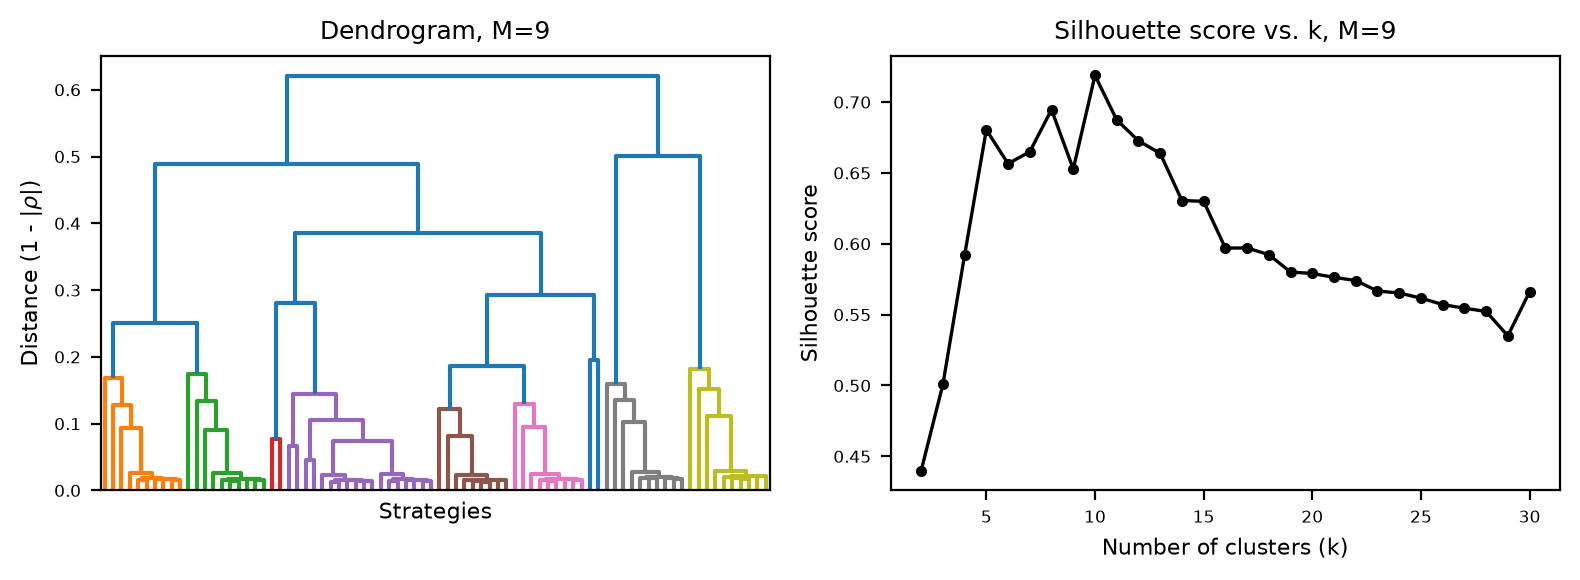

M=9: best_k=10, silhouette=0.7188

10-asset (wide M) universe
X_train: (5158, 1680), X_test: (1290, 1680)

Stage 1: clustering (target-blind)...
  M=2: 240 strategies -> best_k=28 (silhouette=0.2419)
  M=3: 240 strategies -> best_k=30 (silhouette=0.2852)
  M=4: 240 strategies -> best_k=27 (silhouette=0.2987)
  M=5: 240 strategies -> best_k=27 (silhouette=0.3517)
  M=6: 240 strategies -> best_k=11 (silhouette=0.4144)
  M=7: 240 strategies -> best_k=27 (silhouette=0.5279)
  M=8: 240 strategies -> best_k=8 (silhouette=0.5512)
Representatives per M:
source_M
2    28
3    30
4    27
5    27
6    11
7    27
8     8
dtype: int64
Stage 2 (Lasso, alpha=0.000003): 28 / 158 active, in-sample R²=0.5376
Out-of-sample R²: 0.4417

Final strategies, sorted by weight:
                                                                                                         M    T   N    weight
strategy                                                                                                        

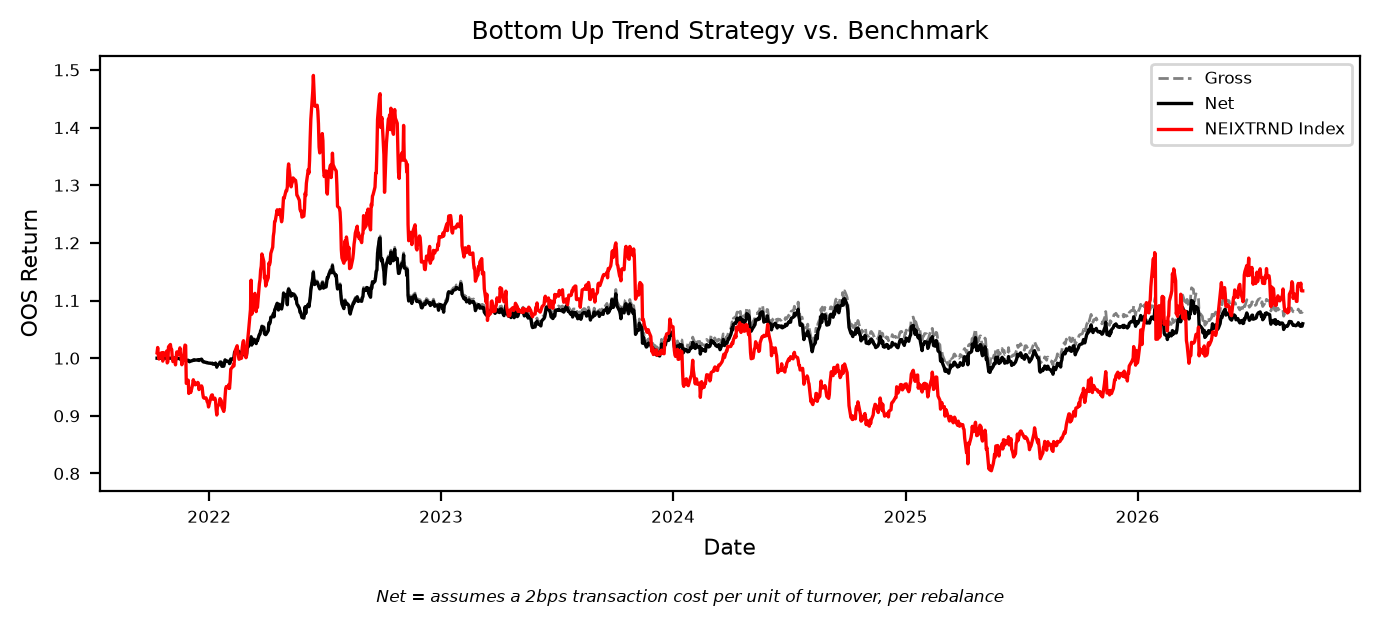

In [6]:
# ============================================================================
# Two-stage pipeline: Stage 1 = target-blind hierarchical clustering,
# Stage 2 = non-negative Lasso on the cluster medoids. Run once per universe.
# ============================================================================
def run_two_stage_pipeline(returns_train: pd.DataFrame, returns_test: pd.DataFrame,
                            asset_class_map: dict, universe: list, label: str,
                            M_grid=(3, 6, 9)) -> dict:
    print(f"\n{'='*70}\n{label} universe\n{'='*70}")

    # Build strategy universes (train + test, same seed/grids -> same columns)
    X_train, meta_train = build_strategy_universe(returns_train, asset_class_map, universe, M_grid=M_grid)
    X_test, meta_test = build_strategy_universe(returns_test, asset_class_map, universe, M_grid=M_grid)
    y_train = returns_train["NEIXTRND Index"].values
    y_test = returns_test["NEIXTRND Index"].values
    print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

    # Stage 1: clustering (target-blind)
    print("\nStage 1: clustering (target-blind)...")
    rep_info = cluster_and_select_medoids(X_train, meta_train, per_group=True)
    print(f"Representatives per M:\n{rep_info.groupby('source_M').size()}")
    selected_cols = rep_info.index.tolist()

    # Stage 2: non-negative Lasso on the medoids
    beta_lasso, r2_lasso, best_alpha = refit_nonneg_lasso(X_train, y_train, selected_cols)
    active_cols = [c for c, w in zip(selected_cols, beta_lasso) if w != 0]
    active_weights = np.array([w for w in beta_lasso if w != 0])
    print(f"Stage 2 (Lasso, alpha={best_alpha:.6f}): "
          f"{len(active_cols)} / {len(selected_cols)} active, in-sample R²={r2_lasso:.4f}")

    # Out-of-sample evaluation (weights fixed from training, no refitting)
    fitted_test = X_test[active_cols].values @ active_weights
    ss_res = np.sum((y_test - fitted_test) ** 2)
    ss_tot = np.sum((y_test - y_test.mean()) ** 2)
    r2_oos = 1 - ss_res / ss_tot
    print(f"Out-of-sample R²: {r2_oos:.4f}")

    fitted_test_series = pd.Series(fitted_test, index=returns_test.index)

    final_meta = meta_train.loc[active_cols].copy()
    final_meta["weight"] = active_weights
    print("\nFinal strategies, sorted by weight:")
    print(final_meta[["M", "T", "N", "weight"]].sort_values("weight", ascending=False).to_string())

    return {
        "label": label,
        "X_train": X_train, "meta_train": meta_train,
        "X_test": X_test, "meta_test": meta_test,
        "active_cols": active_cols, "weights": active_weights,
        "r2_in": r2_lasso, "r2_oos": r2_oos,
        "fitted_test_series": fitted_test_series,
        "y_test_series": pd.Series(y_test, index=returns_test.index),
    }


# ============================================================================
# Run both universes
# ============================================================================
# Paper's grid (default, no change needed at the call site)
# ============================================================================
# Re-run results_10 (if not already in memory)
# ============================================================================
results_10 = run_two_stage_pipeline(
    df_original_diff_train, df_original_diff_test,
    ASSET_CLASS_MAP_10, ASSETS_10, "10-asset"
)

# Full range instead
results_10_wide = run_two_stage_pipeline(
    df_original_diff_train, df_original_diff_test,
    ASSET_CLASS_MAP_10, ASSETS_10, "10-asset (wide M)",
    M_grid=np.arange(2, 9, 1)
)


# --- Dendrogram + silhouette chart, M=9 (the most tightly-clustered group) ---
Z_9, best_k_9, scores_9 = plot_dendrogram_and_silhouette(
    results_10["X_train"], results_10["meta_train"], m_val=9
)
print(f"M=9: best_k={best_k_9}, silhouette={scores_9[best_k_9]:.4f}")

# Full range instead
results_10_wide = run_two_stage_pipeline(
    df_original_diff_train, df_original_diff_test,
    ASSET_CLASS_MAP_10, ASSETS_10, "10-asset (wide M)",
    M_grid=np.arange(2, 9, 1)
)


# ============================================================================
# Build the SAME strategy universe (M grid = (3,6,9), same seed) but with
# transaction cost / turnover tracking, so we can cost-adjust results_10's
# already-fitted weights without changing the selection or weighting at all.
# ============================================================================
X_gross_train_10, X_net_train_10, X_turnover_train_10, meta_costed_train_10 = build_strategy_universe_costed(
    df_original_diff_train, ASSET_CLASS_MAP_10, ASSETS_10,
    M_grid=(3, 6, 9), cost_bps=0.0002
)
X_gross_test_10, X_net_test_10, X_turnover_test_10, meta_costed_test_10 = build_strategy_universe_costed(
    df_original_diff_test, ASSET_CLASS_MAP_10, ASSETS_10,
    M_grid=(3, 6, 9), cost_bps=0.0002
)

# Sanity check: gross returns should exactly match results_10's original X_test
sample_col = results_10["active_cols"][0]
print("Max abs diff, gross vs original (should be ~0):",
      (results_10["X_test"][sample_col] - X_gross_test_10[sample_col]).abs().max())

# Apply results_10's already-fitted weights to the NET (cost-adjusted) test returns
port_test_10 = portfolio_net_returns_and_turnover(
    X_net_test_10, X_turnover_test_10, results_10["active_cols"], results_10["weights"]
)

print(f"\n19-Strategy Replication — OOS average daily turnover: {port_test_10['avg_daily_turnover_pct']:.4f}%")
# ============================================================================
# Apply results_10's fitted weights to the NET (cost-adjusted) test returns
# ============================================================================
port_test_10 = portfolio_net_returns_and_turnover(
    X_net_test_10, X_turnover_test_10, results_10["active_cols"], results_10["weights"]
)

net_oos_series = port_test_10["net_returns"]
gross_oos_series = results_10["fitted_test_series"]

for name, series in [("Gross (no costs)", gross_oos_series), ("Net (2bps costs)", net_oos_series)]:
    ann_ret = series.mean() * 252
    ann_vol = series.std() * np.sqrt(252)
    print(f"{name}: ann. return={ann_ret:.2%}, ann. vol={ann_vol:.2%}, Sharpe={ann_ret/ann_vol:.3f}")

print(f"\nOOS average daily turnover: {port_test_10['avg_daily_turnover_pct']:.4f}%")


# ============================================================================
# Full net-of-cost table, with real turnover filled in
# ============================================================================
table3_net_19 = build_table3_style(
    port_test_10["net_returns"], results_10["y_test_series"],
    "19-Strategy Replication (net of costs)", "NEIXTRND Index",
    turnover_a=port_test_10["avg_daily_turnover_pct"], turnover_b=None
)
print(table3_net_19)

# ============================================================================
# Chart: gross vs. net vs. benchmark
# ============================================================================
fig, ax = plt.subplots(dpi=200, figsize=(7, 3))

cum_gross = (1 + gross_oos_series).cumprod()
cum_net = (1 + net_oos_series).cumprod()
cum_bench = (1 + results_10["y_test_series"]).cumprod()

ax.plot(cum_gross.index, cum_gross.values, color='gray', lw=1.0, linestyle='--', label="Gross")
ax.plot(cum_net.index, cum_net.values, color='black', lw=1.2, label="Net")
ax.plot(cum_bench.index, cum_bench.values, color='red', lw=1.2, label="NEIXTRND Index")

ax.set_xlabel("Date", fontsize=8)
ax.set_ylabel("OOS Return", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Bottom Up Trend Strategy vs. Benchmark", fontsize=9)

fig.text(0.5, -0.02, "Net = assumes a 2bps transaction cost per unit of turnover, per rebalance",
          ha="center", fontsize=6, style="italic", color="black")

plt.tight_layout()
plt.show()

Max abs diff, gross vs original (should be ~0): 0.0

Wide-M Replication — OOS average daily turnover: 9.1751%
Gross (no costs): ann. return=1.66%, ann. vol=9.63%, Sharpe=0.172
Net (2bps costs): ann. return=1.19%, ann. vol=9.63%, Sharpe=0.124
                      Wide-M Replication (net of costs) NEIXTRND Index
Start Date                                  11 Oct 2021    11 Oct 2021
End Date                                    18 Sep 2026    18 Sep 2026
Annualized Returns                                1.19%          4.40%
Annualized Volatility                             9.63%         21.07%
Max Drawdown                                     21.50%         46.01%
Sharpe Ratio                                       0.12           0.21
Daily Turnover                                    9.18%            N/A
Skew                                              -0.49          -1.13


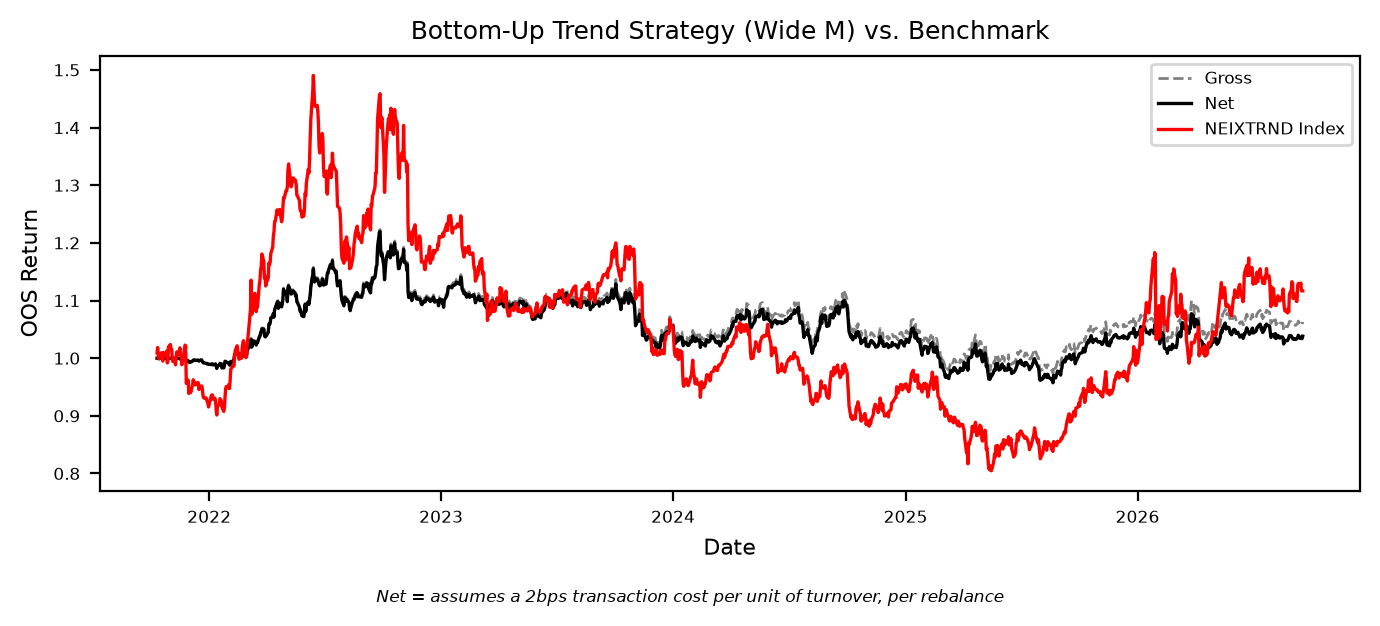

In [7]:
# ============================================================================
# Build the SAME strategy universe as results_10_wide (M grid = 2..8, same
# seed) but with transaction cost / turnover tracking, so we can cost-adjust
# results_10_wide's already-fitted weights without changing selection/weights.
# ============================================================================
X_gross_train_wide, X_net_train_wide, X_turnover_train_wide, meta_costed_train_wide = build_strategy_universe_costed(
    df_original_diff_train, ASSET_CLASS_MAP_10, ASSETS_10,
    M_grid=np.arange(2, 9, 1), cost_bps=0.0002
)
X_gross_test_wide, X_net_test_wide, X_turnover_test_wide, meta_costed_test_wide = build_strategy_universe_costed(
    df_original_diff_test, ASSET_CLASS_MAP_10, ASSETS_10,
    M_grid=np.arange(2, 9, 1), cost_bps=0.0002
)

# Sanity check: gross returns should exactly match results_10_wide's original X_test
sample_col_wide = results_10_wide["active_cols"][0]
print("Max abs diff, gross vs original (should be ~0):",
      (results_10_wide["X_test"][sample_col_wide] - X_gross_test_wide[sample_col_wide]).abs().max())

# Apply results_10_wide's already-fitted weights to the NET (cost-adjusted) test returns
port_test_wide = portfolio_net_returns_and_turnover(
    X_net_test_wide, X_turnover_test_wide, results_10_wide["active_cols"], results_10_wide["weights"]
)

print(f"\nWide-M Replication — OOS average daily turnover: {port_test_wide['avg_daily_turnover_pct']:.4f}%")

net_oos_series_wide = port_test_wide["net_returns"]
gross_oos_series_wide = results_10_wide["fitted_test_series"]

for name, series in [("Gross (no costs)", gross_oos_series_wide), ("Net (2bps costs)", net_oos_series_wide)]:
    ann_ret = series.mean() * 252
    ann_vol = series.std() * np.sqrt(252)
    print(f"{name}: ann. return={ann_ret:.2%}, ann. vol={ann_vol:.2%}, Sharpe={ann_ret/ann_vol:.3f}")

# ============================================================================
# Full net-of-cost table, with real turnover filled in
# ============================================================================
table3_net_wide = build_table3_style(
    port_test_wide["net_returns"], results_10_wide["y_test_series"],
    "Wide-M Replication (net of costs)", "NEIXTRND Index",
    turnover_a=port_test_wide["avg_daily_turnover_pct"], turnover_b=None
)
print(table3_net_wide)    

# ============================================================================
# Chart: gross vs. net vs. benchmark
# ============================================================================
fig, ax = plt.subplots(dpi=200, figsize=(7, 3))

cum_gross_wide = (1 + gross_oos_series_wide).cumprod()
cum_net_wide = (1 + net_oos_series_wide).cumprod()
cum_bench_wide = (1 + results_10_wide["y_test_series"]).cumprod()

ax.plot(cum_gross_wide.index, cum_gross_wide.values, color='gray', lw=1.0, linestyle='--', label="Gross")
ax.plot(cum_net_wide.index, cum_net_wide.values, color='black', lw=1.2, label="Net")
ax.plot(cum_bench_wide.index, cum_bench_wide.values, color='red', lw=1.2, label="NEIXTRND Index")

ax.set_xlabel("Date", fontsize=8)
ax.set_ylabel("OOS Return", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Bottom-Up Trend Strategy (Wide M) vs. Benchmark", fontsize=9)

fig.text(0.5, -0.02, "Net = assumes a 2bps transaction cost per unit of turnover, per rebalance",
          ha="center", fontsize=6, style="italic", color="black")

plt.tight_layout()
plt.show()

## Top-down 

In [8]:

asset_cols = [c for c in df_original_diff_train.columns if c != "NEIXTRND Index"]
n_assets = len(asset_cols)


H_train_wins = winsorize_returns_train_stats(
    df_original_diff_train[asset_cols], df_original_diff_train[asset_cols], n_std=5.0
).values
H_test_wins = winsorize_returns_train_stats(
    df_original_diff_test[asset_cols], df_original_diff_train[asset_cols], n_std=5.0
).values

H_train_raw = df_original_diff_train[asset_cols].values
H_test_raw = df_original_diff_test[asset_cols].values

z_train = df_original_diff_train["NEIXTRND Index"].values
z_test = df_original_diff_test["NEIXTRND Index"].values
y_test_series = pd.Series(z_test, index=df_original_diff_test.index)

bottom_up_series = results_10["fitted_test_series"]


# Combined

In [9]:


window_grid = [10, 21, 42, 63]
N_grid = [5, 10, 21]

cv_window_N_results = cv_select_window_and_N(
    df_original_diff_train, asset_cols, "NEIXTRND Index", window_grid, N_grid
)
print(cv_window_N_results.to_string())

window_grid_small = [21, 63]
N_grid_small = [10, 21]

cv_window_N_small = cv_select_window_and_N(
    df_original_diff_train, asset_cols, "NEIXTRND Index", window_grid_small, N_grid_small
)
print(cv_window_N_small.to_string())

c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.382214e-10, tolerance: 1.713e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.695402e-10, tolerance: 1.713e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.053175e-10, tolerance: 1.713e

  window=10, N=5: R²=0.0062


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.382214e-10, tolerance: 1.713e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.695402e-10, tolerance: 1.713e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.053175e-10, tolerance: 1.713e

  window=10, N=10: R²=-0.0655


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.565032e-08, tolerance: 8.647e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.000167e-08, tolerance: 1.786e-09
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.439487e-09, tolerance: 4.027e

...

  window=42, N=5: R²=0.2535


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.317852e-10, tolerance: 2.775e-10
  model = cd_fast.enet_coordinate_descent_gram(


  window=42, N=10: R²=0.1567
  window=42, N=21: R²=0.1419
  window=63, N=5: R²=0.3054
  window=63, N=10: R²=0.2346
  window=63, N=21: R²=0.0733
    window   N  walkforward_r2
3       21   5        0.360732
9       63   5        0.305429
4       21  10        0.278522
6       42   5        0.253471
10      63  10        0.234624
7       42  10        0.156684
5       21  21        0.142145
8       42  21        0.141889
11      63  21        0.073340
0       10   5        0.006227
1       10  10       -0.065451
2       10  21       -0.717191
  window=21, N=10: R²=0.2785


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.588011e-09, tolerance: 2.307e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.913371e-09, tolerance: 2.307e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.227860e-09, tolerance: 2.307e

  window=21, N=21: R²=0.1421
  window=63, N=10: R²=0.2346
  window=63, N=21: R²=0.0733
   window   N  walkforward_r2
0      21  10        0.278522
2      63  10        0.234624
1      21  21        0.142145
3      63  21        0.073340


In [10]:

# Compare N=5 vs N=10, both at window=21, net of the same 2bps cost, on the
# genuine held-out test period
full_returns = pd.concat([df_original_diff_train, df_original_diff_test])

for N_test in [5, 10]:
    result = rolling_lasso_with_turnover(full_returns, asset_cols, "NEIXTRND Index",
                                          window=21, N=N_test)
    net_test = result["net"][df_original_diff_test.index]
    turnover_test = result["turnover"][df_original_diff_test.index]

    nonzero = net_test != 0
    y_valid = full_returns.loc[df_original_diff_test.index, "NEIXTRND Index"][nonzero]
    net_valid = net_test[nonzero]

    r2_net = 1 - np.sum((y_valid - net_valid)**2) / np.sum((y_valid - y_valid.mean())**2)
    ann_ret = net_valid.mean() * 252
    ann_vol = net_valid.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol
    avg_turnover = turnover_test[turnover_test > 0].mean()  # average PER REBALANCE, not per day

    print(f"\nwindow=21, N={N_test}:")
    print(f"  Net R²: {r2_net:.4f}, Net Sharpe: {sharpe:.4f}")
    print(f"  Avg turnover per rebalance: {avg_turnover:.4f}")
    print(f"  Number of rebalances: {(turnover_test > 0).sum()}")

c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.542452e-09, tolerance: 6.400e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.092734e-09, tolerance: 6.400e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.671768e-09, tolerance: 9.129e


window=21, N=5:
  Net R²: 0.4614, Net Sharpe: 0.3253
  Avg turnover per rebalance: 1.6169
  Number of rebalances: 252


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.598307e-09, tolerance: 6.524e-10
  model = cd_fast.enet_coordinate_descent_gram(



window=21, N=10:
  Net R²: 0.3903, Net Sharpe: 0.1847
  Avg turnover per rebalance: 1.9333
  Number of rebalances: 127


c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.204733e-09, tolerance: 5.514e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.552769e-09, tolerance: 2.824e-10
  model = cd_fast.enet_coordinate_descent(
c:\Code\envs\py314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.359614e-09, tolerance: 3.874e

Covariance matrix (in bps, matching the paper's units):
                          NEIXTRND  Bottom-up  Top-down (Rolling Lasso)
NEIXTRND                      1.87       0.60                      1.03
Bottom-up                     0.60       0.37                      0.39
Top-down (Rolling Lasso)      1.03       0.39                      1.16

Correlation matrix:
                          NEIXTRND  Bottom-up  Top-down (Rolling Lasso)
NEIXTRND                     1.000      0.722                     0.697
Bottom-up                    0.722      1.000                     0.601
Top-down (Rolling Lasso)     0.697      0.601                     1.000
                      Equal-Weight Combined Replication (Net of Costs)  \
Start Date                                                 03 Nov 2021   
End Date                                                   15 Sep 2026   
Annualized Returns                                               6.17%   
Annualized Volatility                              

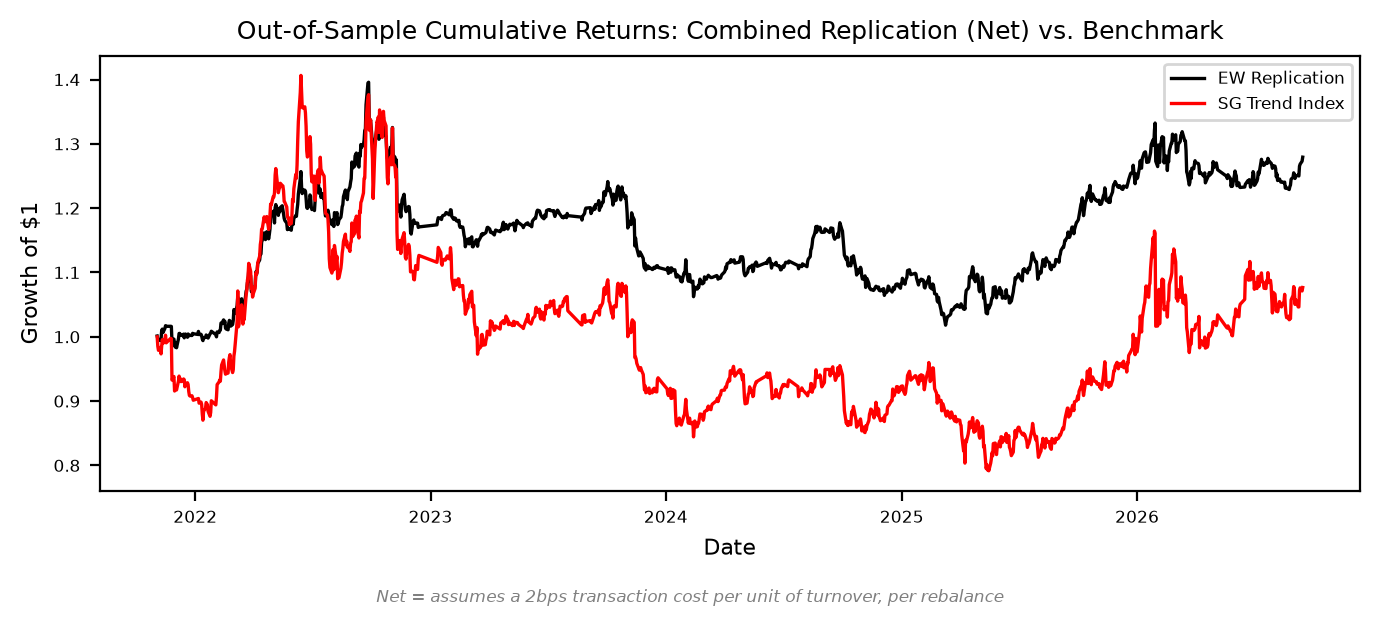

In [11]:
# ============================================================================
# Rebuild the top-down series using rolling Lasso (window=25, N=5),
# net of transaction costs
# ============================================================================
full_returns = pd.concat([df_original_diff_train, df_original_diff_test])
result_lasso_topdown = rolling_lasso_with_turnover(
    full_returns, asset_cols, "NEIXTRND Index", window=25, N=5
)

topdown_lasso_series = result_lasso_topdown["net"][df_original_diff_test.index]
topdown_lasso_series = topdown_lasso_series[topdown_lasso_series != 0]

# Use the NET (2bps-costed) bottom-up series, not the gross one, for a
# fair, consistent comparison -- this assumes port_test_10 already exists
# from your earlier cost-adjustment step (build_strategy_universe_costed +
# portfolio_net_returns_and_turnover on results_10's fitted weights)
bottom_up_net_series = port_test_10["net_returns"]

# Align everything to the same set of dates
combined_df = pd.DataFrame({
    "NEIXTRND": y_test_series,
    "Bottom-up": bottom_up_net_series,
    "Top-down (Rolling Lasso)": topdown_lasso_series,
}).dropna()

# ============================================================================
# Covariance / correlation matrices (paper's Table format)
# ============================================================================
print("Covariance matrix (in bps, matching the paper's units):")
print((combined_df.cov() * 1e4).round(2))

print("\nCorrelation matrix:")
print(combined_df.corr().round(3))

# ============================================================================
# Equal-weight combined replication (both legs net of costs)
# ============================================================================
combined_returns_lasso = 0.5 * combined_df["Bottom-up"] + 0.5 * combined_df["Top-down (Rolling Lasso)"]

table3_combined_lasso = build_table3_style(
    combined_returns_lasso, combined_df["NEIXTRND"],
    "Equal-Weight Combined Replication (Net of Costs)", "NEIXTRND Index"
)
print(table3_combined_lasso)

# ============================================================================
# Full four-way summary table (all net of costs)
# ============================================================================
all_four_lasso = pd.DataFrame({
    "NEIXTRND": combined_df["NEIXTRND"],
    "Bottom-up": combined_df["Bottom-up"],
    "Top-down": combined_df["Top-down (Rolling Lasso)"],
    "EW Combined": combined_returns_lasso,
})

summary_rows = []
for name, r in all_four_lasso.items():
    cum = (1 + r).cumprod()
    ann_ret = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    summary_rows.append({
        "Ann. Return": f"{ann_ret:.2%}",
        "Ann. Vol": f"{ann_vol:.2%}",
        "Sharpe": f"{ann_ret/ann_vol:.2f}",
        "Max Drawdown": f"{abs(max_drawdown(cum)):.2%}",
        "Corr. to NEIXTRND": f"{r.corr(combined_df['NEIXTRND']):.3f}",
    })

summary_table_lasso = pd.DataFrame(summary_rows, index=all_four_lasso.columns)
print(summary_table_lasso)

# ============================================================================
# Chart, with the net-of-cost footnote
# ============================================================================
cum_combined = (1 + combined_returns_lasso).cumprod()
cum_bench = (1 + combined_df["NEIXTRND"]).cumprod()

fig, ax = plt.subplots(dpi=200, figsize=(7, 3))
ax.plot(cum_combined.index, cum_combined.values, color='black', lw=1.2, label="EW Replication")
ax.plot(cum_bench.index, cum_bench.values, color='red', lw=1.2, label="SG Trend Index")
ax.set_xlabel("Date", fontsize=8)
ax.set_ylabel("Growth of $1", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Out-of-Sample Cumulative Returns: Combined Replication (Net) vs. Benchmark", fontsize=9)
fig.text(0.5, -0.02, "Net = assumes a 2bps transaction cost per unit of turnover, per rebalance",
          ha="center", fontsize=6, style="italic", color="gray")
plt.tight_layout()
plt.show()

In [12]:
weekly_returns_combined = combined_returns_lasso.resample("W").apply(lambda r: (1+r).prod()-1)
weekly_returns_bench = combined_df["NEIXTRND"].resample("W").apply(lambda r: (1+r).prod()-1)

aligned = pd.DataFrame({"combined": weekly_returns_combined, "bench": weekly_returns_bench}).dropna()

def suffix_cumulative_returns(weekly_returns: pd.Series) -> np.ndarray:
    """
    For each possible entry week i, returns the cumulative return from
    entering at week i and holding through the END of the series.
    Result[0] = full-period return (enter at week 1, hold everything).
    Result[-1] = just the last week's own return.
    """
    r = weekly_returns.values
    n = len(r)
    reversed_cumprod = np.cumprod(1 + r[::-1])  # suffix products, built from the end backward
    suffix_returns = reversed_cumprod[::-1] - 1   # flip back to chronological entry-week order
    return suffix_returns


suffix_combined = suffix_cumulative_returns(aligned["combined"])
suffix_bench = suffix_cumulative_returns(aligned["bench"])

print(f"Number of entry weeks: {len(suffix_combined)}")
print(f"First value (entry at week 1, full-period return): {suffix_combined[0]:.4%}")
print(f"Last value (entry at final week, 1 week's return): {suffix_combined[-1]:.4%}")

Number of entry weeks: 255
First value (entry at week 1, full-period return): 27.9298%
Last value (entry at final week, 1 week's return): 0.8563%


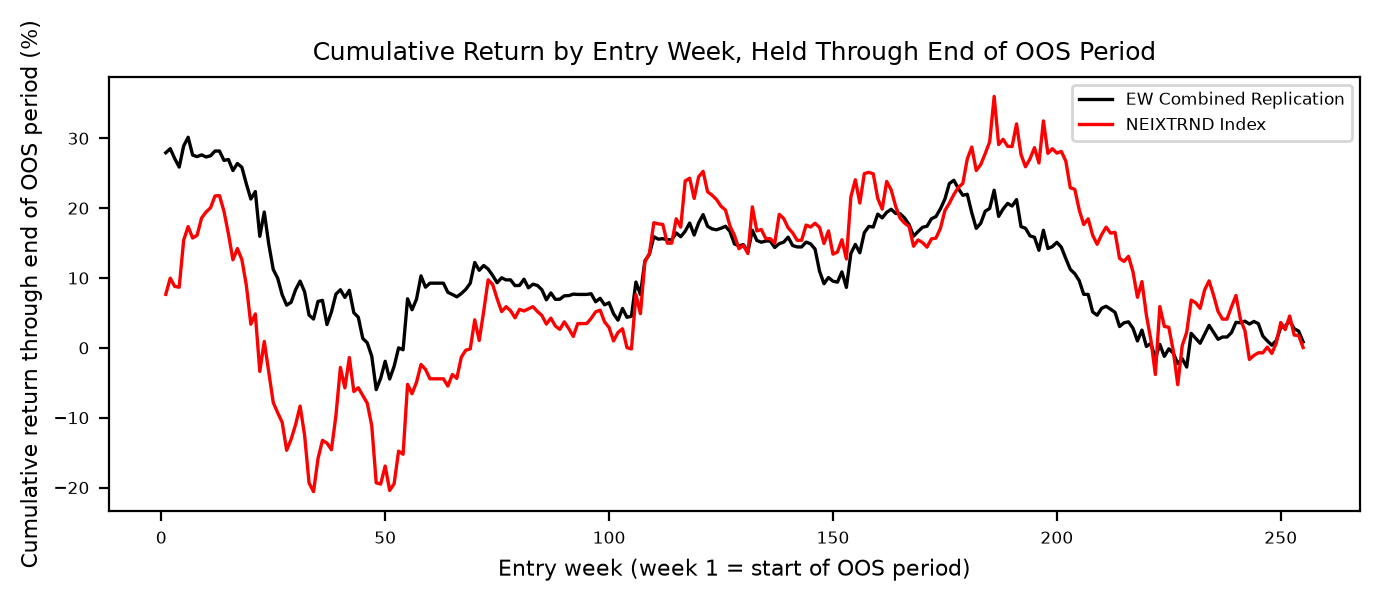

In [13]:
fig, ax = plt.subplots(dpi=200, figsize=(7, 3))

ax.plot(range(1, len(suffix_combined) + 1), suffix_combined * 100,
        color='black', lw=1.2, label="EW Combined Replication")
ax.plot(range(1, len(suffix_bench) + 1), suffix_bench * 100,
        color='red', lw=1.2, label="NEIXTRND Index")

ax.set_xlabel("Entry week (week 1 = start of OOS period)", fontsize=8)
ax.set_ylabel("Cumulative return through end of OOS period (%)", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Cumulative Return by Entry Week, Held Through End of OOS Period", fontsize=9)

plt.tight_layout()
plt.show()

In [14]:
weekly_returns_bottomup = combined_df["Bottom-up"].resample("W").apply(lambda r: (1+r).prod()-1)
weekly_returns_topdown = combined_df["Top-down (Rolling Lasso)"].resample("W").apply(lambda r: (1+r).prod()-1)

aligned_all = pd.DataFrame({
    "combined": weekly_returns_combined,
    "bench": weekly_returns_bench,
    "bottomup": weekly_returns_bottomup,
    "topdown": weekly_returns_topdown,
}).dropna()

suffix_combined = suffix_cumulative_returns(aligned_all["combined"])
suffix_bench = suffix_cumulative_returns(aligned_all["bench"])
suffix_bottomup = suffix_cumulative_returns(aligned_all["bottomup"])
suffix_topdown = suffix_cumulative_returns(aligned_all["topdown"])
""""
print(f"Number of entry weeks: {len(suffix_combined)}")

fig, ax = plt.subplots(dpi=200, figsize=(7, 3))

ax.plot(range(1, len(suffix_combined) + 1), suffix_combined * 100,
        color='black', lw=1.2, label="EW Combined")
ax.plot(range(1, len(suffix_bench) + 1), suffix_bench * 100,
        color='red', lw=1.2, label="NEIXTRND Index")
ax.plot(range(1, len(suffix_bottomup) + 1), suffix_bottomup * 100,
        color='blue', lw=1.0, label="Bottom-up")
ax.plot(range(1, len(suffix_topdown) + 1), suffix_topdown * 100,
        color='green', lw=1.0, label="Top-down (Rolling Lasso)")

ax.set_xlabel("Entry week (week 1 = start of OOS period)", fontsize=8)
ax.set_ylabel("Cumulative return through end of OOS period (%)", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Cumulative Return by Entry Week, Held Through End of OOS Period", fontsize=9)

plt.tight_layout()
plt.show()
"""

'"\nprint(f"Number of entry weeks: {len(suffix_combined)}")\n\nfig, ax = plt.subplots(dpi=200, figsize=(7, 3))\n\nax.plot(range(1, len(suffix_combined) + 1), suffix_combined * 100,\n        color=\'black\', lw=1.2, label="EW Combined")\nax.plot(range(1, len(suffix_bench) + 1), suffix_bench * 100,\n        color=\'red\', lw=1.2, label="NEIXTRND Index")\nax.plot(range(1, len(suffix_bottomup) + 1), suffix_bottomup * 100,\n        color=\'blue\', lw=1.0, label="Bottom-up")\nax.plot(range(1, len(suffix_topdown) + 1), suffix_topdown * 100,\n        color=\'green\', lw=1.0, label="Top-down (Rolling Lasso)")\n\nax.set_xlabel("Entry week (week 1 = start of OOS period)", fontsize=8)\nax.set_ylabel("Cumulative return through end of OOS period (%)", fontsize=8)\nax.tick_params(labelsize=6)\nax.legend(fontsize=6)\nax.set_title("Cumulative Return by Entry Week, Held Through End of OOS Period", fontsize=9)\n\nplt.tight_layout()\nplt.show()\n'

In [15]:
def suffix_annualized_vol(weekly_returns: pd.Series, periods_per_year: int = 52) -> np.ndarray:
    """
    For each possible entry week i, computes the annualized volatility of
    returns from week i through the end of the series.
    """
    r = weekly_returns.values
    n = len(r)
    vols = np.full(n, np.nan)
    for i in range(n):
        sub = r[i:]
        if len(sub) > 1:
            vols[i] = sub.std() * np.sqrt(periods_per_year)
    return vols


def suffix_max_drawdown(weekly_returns: pd.Series) -> np.ndarray:
    """
    For each possible entry week i, computes the max drawdown of the
    cumulative return path starting fresh at week i (i.e., entering at i
    resets the "peak" to 1.0 at that point).
    """
    r = weekly_returns.values
    n = len(r)
    mdds = np.zeros(n)
    for i in range(n):
        sub = r[i:]
        cum = (1 + sub).cumprod()
        running_max = np.maximum.accumulate(cum)
        drawdown = (cum - running_max) / running_max
        mdds[i] = drawdown.min()
    return mdds


vol_combined = suffix_annualized_vol(aligned_all["combined"])
vol_bench = suffix_annualized_vol(aligned_all["bench"])
vol_bottomup = suffix_annualized_vol(aligned_all["bottomup"])
vol_topdown = suffix_annualized_vol(aligned_all["topdown"])

mdd_combined = suffix_max_drawdown(aligned_all["combined"])
mdd_bench = suffix_max_drawdown(aligned_all["bench"])
mdd_bottomup = suffix_max_drawdown(aligned_all["bottomup"])
mdd_topdown = suffix_max_drawdown(aligned_all["topdown"])

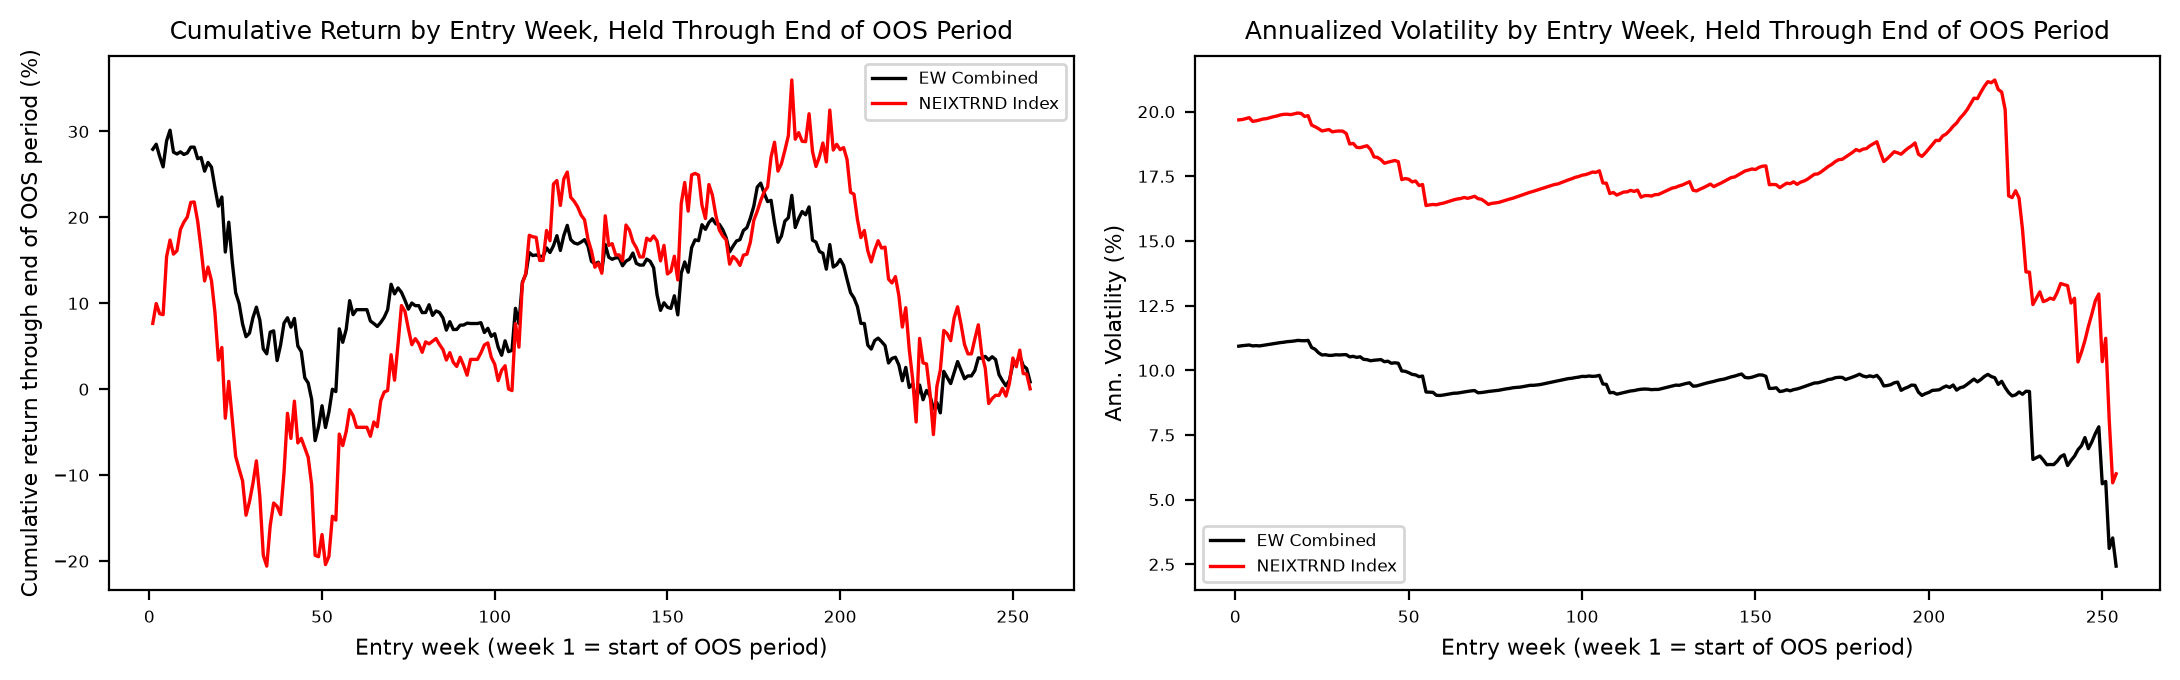

In [16]:
fig, axes = plt.subplots(1, 2, dpi=200, figsize=(11, 3.5))

# --- Left panel: Cumulative Return by Entry Week (Combined vs. Benchmark only) ---
ax = axes[0]
ax.plot(range(1, len(suffix_combined) + 1), suffix_combined * 100,
        color='black', lw=1.2, label="EW Combined")
ax.plot(range(1, len(suffix_bench) + 1), suffix_bench * 100,
        color='red', lw=1.2, label="NEIXTRND Index")
ax.set_xlabel("Entry week (week 1 = start of OOS period)", fontsize=8)
ax.set_ylabel("Cumulative return through end of OOS period (%)", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Cumulative Return by Entry Week, Held Through End of OOS Period", fontsize=9)

# --- Right panel: Annualized Volatility by Entry Week (Combined vs. Benchmark only) ---
ax = axes[1]
ax.plot(range(1, len(vol_combined)+1), vol_combined*100, color='black', lw=1.2, label="EW Combined")
ax.plot(range(1, len(vol_bench)+1), vol_bench*100, color='red', lw=1.2, label="NEIXTRND Index")
ax.set_xlabel("Entry week (week 1 = start of OOS period)", fontsize=8)
ax.set_ylabel("Ann. Volatility (%)", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Annualized Volatility by Entry Week, Held Through End of OOS Period", fontsize=9)

plt.tight_layout()
plt.show()

In [17]:
frac_return_ahead = (suffix_combined > suffix_bench).mean()
frac_vol_lower = (vol_combined < vol_bench).mean()

print(f"Fraction of entry weeks where Combined's cumulative return beats benchmark: {frac_return_ahead:.2%}")
print(f"Fraction of entry weeks where Combined's volatility is lower than benchmark: {frac_vol_lower:.2%}")

# Average magnitude of the vol reduction, where it holds
vol_ratio = vol_combined / vol_bench
print(f"\nAverage vol ratio (Combined / Benchmark) across all entry weeks: {np.nanmean(vol_ratio):.2f}")

Fraction of entry weeks where Combined's cumulative return beats benchmark: 54.90%
Fraction of entry weeks where Combined's volatility is lower than benchmark: 99.61%

Average vol ratio (Combined / Benchmark) across all entry weeks: 0.54


In [18]:
def suffix_sharpe(weekly_returns: pd.Series, periods_per_year: int = 52) -> np.ndarray:
    """
    For each possible entry week i, computes the annualized Sharpe ratio of
    returns from week i through the end of the series.
    """
    r = weekly_returns.values
    n = len(r)
    sharpes = np.full(n, np.nan)
    for i in range(n):
        sub = r[i:]
        if len(sub) > 1 and sub.std() > 0:
            ann_ret = sub.mean() * periods_per_year
            ann_vol = sub.std() * np.sqrt(periods_per_year)
            sharpes[i] = ann_ret / ann_vol
    return sharpes


sharpe_combined = suffix_sharpe(aligned_all["combined"])
sharpe_bench = suffix_sharpe(aligned_all["bench"])

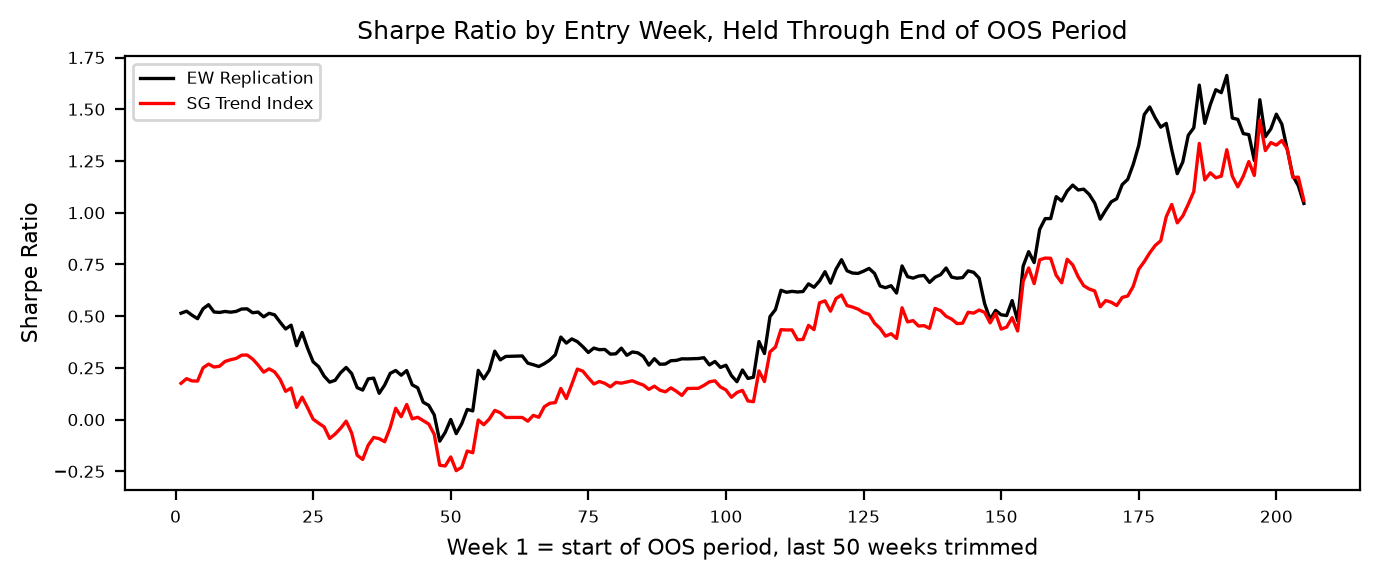

Fraction of entry weeks (trimmed) where Combined's Sharpe beats benchmark's: 98.54%


In [19]:
cutoff_weeks = 50  # drop the final 10 entry points where the denominator gets too noisy

sharpe_combined_trimmed = sharpe_combined[:-cutoff_weeks]
sharpe_bench_trimmed = sharpe_bench[:-cutoff_weeks]

fig, ax = plt.subplots(dpi=200, figsize=(7, 3))

ax.plot(range(1, len(sharpe_combined_trimmed)+1), sharpe_combined_trimmed, color='black', lw=1.2, label="EW Replication")
ax.plot(range(1, len(sharpe_bench_trimmed)+1), sharpe_bench_trimmed, color='red', lw=1.2, label="SG Trend Index")

ax.set_xlabel("Week 1 = start of OOS period, last 50 weeks trimmed", fontsize=8)
ax.set_ylabel("Sharpe Ratio", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title(f"Sharpe Ratio by Entry Week, Held Through End of OOS Period", fontsize=9)

plt.tight_layout()
plt.show()

# Recompute the win-rate stat on the trimmed series too, for consistency
frac_sharpe_ahead_trimmed = (sharpe_combined_trimmed > sharpe_bench_trimmed).mean()
print(f"Fraction of entry weeks (trimmed) where Combined's Sharpe beats benchmark's: {frac_sharpe_ahead_trimmed:.2%}")

In [20]:
frac_sharpe_ahead_50 = (sharpe_combined[:-50] > sharpe_bench[:-50]).mean()
print(f"Fraction of entry weeks (last 50 trimmed) where Combined's Sharpe beats benchmark's: {frac_sharpe_ahead_50:.2%}")

# Check robustness across a few different cutoffs
for cutoff in [10, 20, 30, 50, 75]:
    frac = (sharpe_combined[:-cutoff] > sharpe_bench[:-cutoff]).mean()
    print(f"  cutoff={cutoff}: Combined ahead in {frac:.2%} of remaining entry weeks")

Fraction of entry weeks (last 50 trimmed) where Combined's Sharpe beats benchmark's: 98.54%
  cutoff=10: Combined ahead in 85.31% of remaining entry weeks
  cutoff=20: Combined ahead in 86.38% of remaining entry weeks
  cutoff=30: Combined ahead in 89.78% of remaining entry weeks
  cutoff=50: Combined ahead in 98.54% of remaining entry weeks
  cutoff=75: Combined ahead in 100.00% of remaining entry weeks


In [21]:
import numpy as np
from scipy.stats import norm

EULER_MASCHERONI = 0.5772156649

def expected_max_sr(mean_sr: float, var_sr: float, num_trials: int) -> float:
    """
    Analytic expected maximum Sharpe ratio across `num_trials` trials whose
    individual SR estimates are ~ N(mean_sr, var_sr). (Paper's Eq. 6 / the
    getExpMaxSR function in their Appendix snippet.)
    """
    if num_trials <= 1:
        return mean_sr
    sigma = np.sqrt(var_sr)
    maxZ = ((1 - EULER_MASCHERONI) * norm.ppf(1 - 1.0 / num_trials)
             + EULER_MASCHERONI * norm.ppf(1 - 1.0 / (num_trials * np.e)))
    return mean_sr + sigma * maxZ


def effective_num_trials(M: int, avg_corr: float) -> float:
    """
    Implied number of INDEPENDENT trials N-hat from M actual, correlated
    trials with average pairwise correlation avg_corr. (Eq. 9.)
    """
    avg_corr = np.clip(avg_corr, 0.0, 1.0)
    return avg_corr + (1 - avg_corr) * M


def deflated_sharpe_ratio(sr_hat: float, sr0: float, T: int,
                           skew: float, kurt: float) -> float:
    """
    Probability that the TRUE Sharpe ratio of the selected strategy exceeds
    sr0 (the expected-max-under-multiple-trials threshold), accounting for
    sample length and non-normal returns. (Eq. 2, the DSR itself.)

    IMPORTANT: sr_hat and sr0 must be PER-PERIOD (e.g. daily) Sharpe ratios,
    not annualized -- the sqrt(T-1) scaling assumes this.
    """
    numerator = (sr_hat - sr0) * np.sqrt(T - 1)
    denominator = np.sqrt(1 - skew * sr_hat + ((kurt - 1) / 4) * sr_hat**2)
    return norm.cdf(numerator / denominator)

In [22]:
# Collect every distinct trial evaluated on the same OOS period.
# Fill in with your actual return Series -- example keys shown.
trials = {
    "bottomup_M369_NNLS": results_10["fitted_test_series"],
            
    "bottomup_wideM": results_10_wide["fitted_test_series"],
    "topdown_w21_N10": topdown_lasso_series,                   # original (window=21,N=10)
    
    # etc. -- include the HMM and PCA-spread attempts too if you want full honesty
}

# --- Step 1: align all trials to a common set of dates ---
trials_df = pd.DataFrame(trials).dropna()
M = trials_df.shape[1]
T = trials_df.shape[0]

# --- Step 2: per-trial daily Sharpe (NOT annualized) ---
trial_sharpes = trials_df.mean() / trials_df.std()
print("Per-trial daily Sharpe ratios:")
print(trial_sharpes.sort_values(ascending=False))

# --- Step 3: average pairwise correlation among trial return series ---
corr_matrix = trials_df.corr()
avg_corr = (corr_matrix.values.sum() - M) / (M * (M - 1))  # exclude diagonal
print(f"\nAverage pairwise correlation across {M} trials: {avg_corr:.4f}")

# --- Step 4: effective number of independent trials ---
N_hat = effective_num_trials(M, avg_corr)
print(f"Implied independent trials (N-hat): {N_hat:.2f}")

# --- Step 5: expected maximum Sharpe ratio under N-hat trials ---
mean_sr_trials = trial_sharpes.mean()
var_sr_trials = trial_sharpes.var()
sr0 = expected_max_sr(mean_sr_trials, var_sr_trials, N_hat)
print(f"Expected max SR under {N_hat:.1f} trials (deflation threshold): {sr0:.4f}")

# --- Step 6: DSR for your ACTUAL selected/reported strategy ---
selected_name = "bottomup_M369_NNLS"  # matches an actual key in `trials`  # whichever you report as your headline result
selected_returns = trials_df[selected_name]

sr_hat_selected = selected_returns.mean() / selected_returns.std()
skew_selected = selected_returns.skew()
kurt_selected = selected_returns.kurt() + 3  # pandas .kurt() is EXCESS kurtosis; paper wants raw kurtosis

dsr = deflated_sharpe_ratio(sr_hat_selected, sr0, T, skew_selected, kurt_selected)
print(f"\nSelected strategy: {selected_name}")
print(f"Daily Sharpe: {sr_hat_selected:.4f} (annualized: {sr_hat_selected*np.sqrt(252):.4f})")
print(f"Deflation threshold SR0: {sr0:.4f}")
print(f"Deflated Sharpe Ratio (DSR): {dsr:.4f}")

Per-trial daily Sharpe ratios:
topdown_w21_N10       0.034919
bottomup_M369_NNLS    0.021655
bottomup_wideM        0.019674
dtype: float64

Average pairwise correlation across 3 trials: 0.7297
Implied independent trials (N-hat): 1.54
Expected max SR under 1.5 trials (deflation threshold): 0.0275

Selected strategy: bottomup_M369_NNLS
Daily Sharpe: 0.0217 (annualized: 0.3438)
Deflation threshold SR0: 0.0275
Deflated Sharpe Ratio (DSR): 0.4226


In [23]:
selected_name = "bottomup_M369_NNLS"  # or whichever you want to report as the headline result
selected_returns = trials_df[selected_name]

sr_hat_selected = selected_returns.mean() / selected_returns.std()
skew_selected = selected_returns.skew()
kurt_selected = selected_returns.kurt() + 3  # pandas returns excess kurtosis; paper wants raw

dsr = deflated_sharpe_ratio(sr_hat_selected, sr0, T, skew_selected, kurt_selected)
print(f"\nSelected strategy: {selected_name}")
print(f"Daily Sharpe: {sr_hat_selected:.4f} (annualized: {sr_hat_selected*np.sqrt(252):.4f})")
print(f"Deflation threshold SR0: {sr0:.4f}")
print(f"Skew: {skew_selected:.4f}, Kurtosis (raw): {kurt_selected:.4f}")
print(f"Deflated Sharpe Ratio (DSR): {dsr:.4f}")

selected_returns = combined_returns_lasso

sr_hat_combined = selected_returns.mean() / selected_returns.std()
skew_combined = selected_returns.skew()
kurt_combined = selected_returns.kurt() + 3  # raw kurtosis, matching the paper's convention

dsr_combined = deflated_sharpe_ratio(sr_hat_combined, sr0, len(selected_returns),
                                       skew_combined, kurt_combined)

print(f"EW Combined daily Sharpe: {sr_hat_combined:.4f} (annualized: {sr_hat_combined*np.sqrt(252):.4f})")
print(f"Deflation threshold SR0: {sr0:.4f}")
print(f"Skew: {skew_combined:.4f}, Kurtosis (raw): {kurt_combined:.4f}")
print(f"Deflated Sharpe Ratio (DSR): {dsr_combined:.4f}")


Selected strategy: bottomup_M369_NNLS
Daily Sharpe: 0.0217 (annualized: 0.3438)
Deflation threshold SR0: 0.0275
Skew: -0.5057, Kurtosis (raw): 6.0607
Deflated Sharpe Ratio (DSR): 0.4226
EW Combined daily Sharpe: 0.0322 (annualized: 0.5116)
Deflation threshold SR0: 0.0275
Skew: -0.8932, Kurtosis (raw): 8.6069
Deflated Sharpe Ratio (DSR): 0.5629


In [24]:
def probabilistic_sharpe_ratio(sr_hat: float, sr_benchmark: float, T: int,
                                 skew: float, kurt: float) -> float:
    """
    PSR: probability that the TRUE Sharpe ratio exceeds sr_benchmark
    (commonly 0), given sample length T and the return distribution's
    skew/kurtosis. This is DSR's building block WITHOUT the
    multiple-testing deflation step.
    """
    numerator = (sr_hat - sr_benchmark) * np.sqrt(T - 1)
    denominator = np.sqrt(1 - skew * sr_hat + ((kurt - 1) / 4) * sr_hat**2)
    return norm.cdf(numerator / denominator)


bench_returns = y_test_series  # your benchmark daily return series
sr_hat_bench = bench_returns.mean() / bench_returns.std()
skew_bench = bench_returns.skew()
kurt_bench = bench_returns.kurt() + 3

psr_bench = probabilistic_sharpe_ratio(sr_hat_bench, 0.0, len(bench_returns), skew_bench, kurt_bench)

print(f"Benchmark daily Sharpe: {sr_hat_bench:.4f} (annualized: {sr_hat_bench*np.sqrt(252):.4f})")
print(f"Skew: {skew_bench:.4f}, Kurtosis (raw): {kurt_bench:.4f}")
print(f"Probabilistic Sharpe Ratio (vs. SR=0): {psr_bench:.4f}")

Benchmark daily Sharpe: 0.0132 (annualized: 0.2088)
Skew: -1.1278, Kurtosis (raw): 11.4143
Probabilistic Sharpe Ratio (vs. SR=0): 0.6803


In [25]:
# PSR for your own candidates too, for a true like-for-like comparison with the benchmark
for name, series in trials_df.items():
    sr_hat = series.mean() / series.std()
    skew = series.skew()
    kurt = series.kurt() + 3
    psr = probabilistic_sharpe_ratio(sr_hat, 0.0, len(series), skew, kurt)
    print(f"{name}: daily Sharpe={sr_hat:.4f}, PSR (vs SR=0)={psr:.4f}")

# And for the EW Combined
sr_hat_combined = combined_returns_lasso.mean() / combined_returns_lasso.std()
skew_combined = combined_returns_lasso.skew()
kurt_combined = combined_returns_lasso.kurt() + 3
psr_combined = probabilistic_sharpe_ratio(sr_hat_combined, 0.0, len(combined_returns_lasso),
                                            skew_combined, kurt_combined)
print(f"EW Combined: daily Sharpe={sr_hat_combined:.4f}, PSR (vs SR=0)={psr_combined:.4f}")

bottomup_M369_NNLS: daily Sharpe=0.0217, PSR (vs SR=0)=0.7664
bottomup_wideM: daily Sharpe=0.0197, PSR (vs SR=0)=0.7456
topdown_w21_N10: daily Sharpe=0.0349, PSR (vs SR=0)=0.8769
EW Combined: daily Sharpe=0.0322, PSR (vs SR=0)=0.8581


In [26]:
def get_dist_max_sr(mean_sr: float, var_sr: float, num_trials, num_iters: int = 10000) -> dict:
    """
    Numerically estimates the expected maximum Sharpe ratio across
    num_trials draws from N(mean_sr, var_sr), repeated num_iters times.
    Direct adaptation of the paper's getDistMaxSR (Appendix A.2, Snippet 1).

    num_trials can be a float (e.g. your N_hat after the correlation
    correction) -- we round up to the nearest integer for the simulation,
    since you can't literally draw a fractional number of trials.
    """
    n = int(np.ceil(num_trials))
    sigma = np.sqrt(var_sr)
    max_sr_draws = []
    for _ in range(num_iters):
        draw = np.random.normal(mean_sr, sigma, n)
        max_sr_draws.append(draw.max())
    max_sr_draws = np.array(max_sr_draws)
    return {"mean_max_sr": max_sr_draws.mean(), "std_max_sr": max_sr_draws.std()}


# --- Run the sanity check at your ACTUAL trial parameters ---
num_iters = 10000

# Using N_hat (post correlation-correction, ~1.54 in your case)
numerical_at_Nhat = get_dist_max_sr(mean_sr_trials, var_sr_trials, N_hat, num_iters)
analytical_at_Nhat = expected_max_sr(mean_sr_trials, var_sr_trials, N_hat)

print(f"At N_hat = {N_hat:.2f} (rounded to {int(np.ceil(N_hat))} for simulation):")
print(f"  Analytical expected max SR: {analytical_at_Nhat:.4f}")
print(f"  Numerical (Monte Carlo) mean max SR: {numerical_at_Nhat['mean_max_sr']:.4f} "
      f"(std across {num_iters} iterations: {numerical_at_Nhat['std_max_sr']:.4f})")
print(f"  Discrepancy: {abs(analytical_at_Nhat - numerical_at_Nhat['mean_max_sr']):.4f}")

# Also check at your RAW trial count M (before the correlation correction),
# for context on how much the correlation adjustment itself matters here
numerical_at_M = get_dist_max_sr(mean_sr_trials, var_sr_trials, M, num_iters)
analytical_at_M = expected_max_sr(mean_sr_trials, var_sr_trials, M)

print(f"\nAt raw M = {M} (no correlation correction):")
print(f"  Analytical expected max SR: {analytical_at_M:.4f}")
print(f"  Numerical (Monte Carlo) mean max SR: {numerical_at_M['mean_max_sr']:.4f}")
print(f"  Discrepancy: {abs(analytical_at_M - numerical_at_M['mean_max_sr']):.4f}")

At N_hat = 1.54 (rounded to 2 for simulation):
  Analytical expected max SR: 0.0275
  Numerical (Monte Carlo) mean max SR: 0.0302 (std across 10000 iterations: 0.0069)
  Discrepancy: 0.0027

At raw M = 3 (no correlation correction):
  Analytical expected max SR: 0.0325
  Numerical (Monte Carlo) mean max SR: 0.0324
  Discrepancy: 0.0001


 num_trials  analytical  numerical  discrepancy
          2    0.029724   0.029780     0.000056
          3    0.032485   0.032370     0.000115
          5    0.035301   0.035218     0.000083
         10    0.038468   0.038162     0.000306
         20    0.041171   0.040852     0.000318
         30    0.042602   0.042369     0.000233
         50    0.044284   0.044095     0.000189
         75    0.045539   0.045354     0.000184
        100    0.046392   0.046270     0.000122
        200    0.048339   0.048137     0.000202
        500    0.050718   0.050684     0.000034


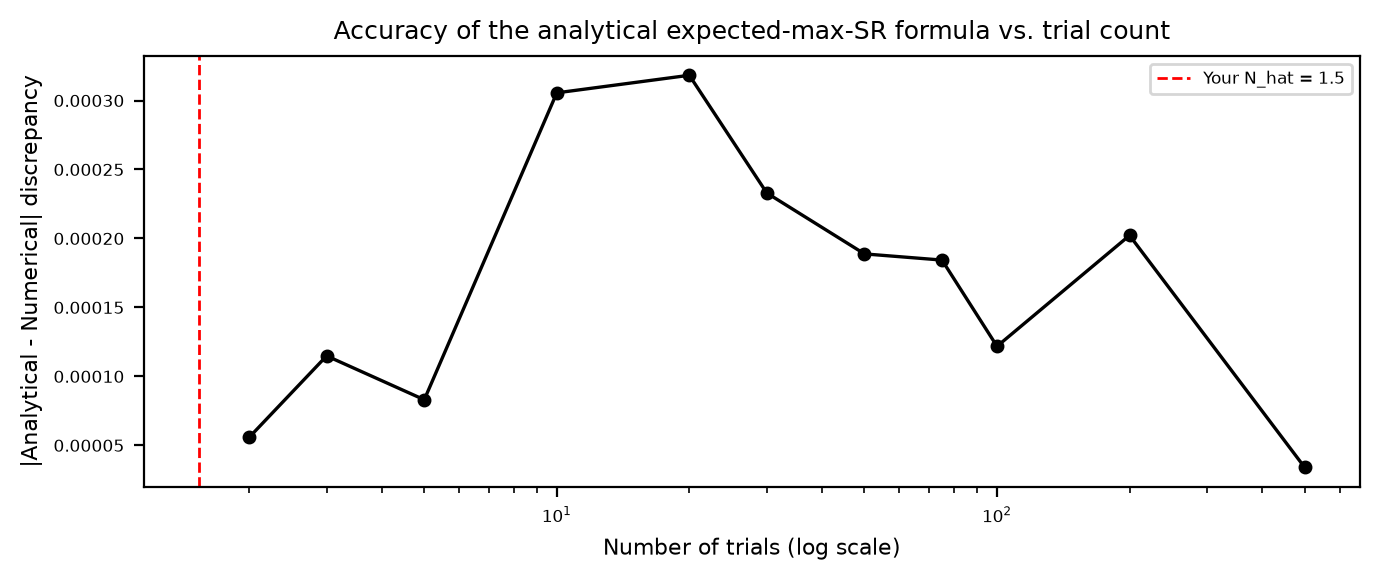

In [27]:
trial_counts = [2, 3, 5, 10, 20, 30, 50, 75, 100, 200, 500]
discrepancies = []

for n in trial_counts:
    numerical = get_dist_max_sr(mean_sr_trials, var_sr_trials, n, num_iters=2000)
    analytical = expected_max_sr(mean_sr_trials, var_sr_trials, n)
    discrepancies.append({
        "num_trials": n,
        "analytical": analytical,
        "numerical": numerical["mean_max_sr"],
        "discrepancy": abs(analytical - numerical["mean_max_sr"]),
    })

discrepancy_df = pd.DataFrame(discrepancies)
print(discrepancy_df.to_string(index=False))

fig, ax = plt.subplots(dpi=200, figsize=(7, 3))
ax.plot(discrepancy_df["num_trials"], discrepancy_df["discrepancy"], color='black', lw=1.2, marker='o', markersize=4)
ax.axvline(N_hat, color='red', lw=1.0, linestyle='--', label=f"Your N_hat = {N_hat:.1f}")
ax.set_xscale("log")
ax.set_xlabel("Number of trials (log scale)", fontsize=8)
ax.set_ylabel("|Analytical - Numerical| discrepancy", fontsize=8)
ax.tick_params(labelsize=6)
ax.legend(fontsize=6)
ax.set_title("Accuracy of the analytical expected-max-SR formula vs. trial count", fontsize=9)
plt.tight_layout()
plt.show()

In [28]:
# ---- Inputs: the trial set (the candidates searched over) ----
trials_df = pd.DataFrame(trials).dropna()          # your 3 trial return series
M = trials_df.shape[1]

trial_sharpes = trials_df.mean() / trials_df.std() # daily Sharpe per trial
corr = trials_df.corr()
avg_corr = (corr.values.sum() - M) / (M * (M - 1)) # mean off-diagonal correlation

var_sr_trials = trial_sharpes.var()                # dispersion across trials
N_hat = effective_num_trials(M, avg_corr)

# ---- Threshold: mean = 0 under H0 (paper's Eq. 2) ----
sr0 = expected_max_sr(0.0, var_sr_trials, N_hat)

# ---- Inputs: the reported strategy (EW Replication) ----
r = combined_returns_lasso
T = len(r)
sr_hat = r.mean() / r.std()                        # daily, NOT annualized
skew = r.skew()
kurt = r.kurt() + 3                                # pandas gives excess kurtosis

# ---- Output ----
psr = probabilistic_sharpe_ratio(sr_hat, 0.0, T, skew, kurt)
dsr = deflated_sharpe_ratio(sr_hat, sr0, T, skew, kurt)

print("--- Trial set ---")
print(trial_sharpes.round(4).to_string())
print(f"M = {M}, avg pairwise corr = {avg_corr:.4f}, N_hat = {N_hat:.3f}")
print(f"Var of trial Sharpes (daily) = {var_sr_trials:.3e}  "
      f"(std = {np.sqrt(var_sr_trials):.4f})")
print(f"SR0 (daily) = {sr0:.4f}  (annualized {sr0*np.sqrt(252):.3f})")
print("\n--- Reported strategy ---")
print(f"T = {T}, SR_hat (daily) = {sr_hat:.4f}  (annualized {sr_hat*np.sqrt(252):.3f})")
print(f"skew = {skew:.3f}, kurtosis (raw) = {kurt:.3f}")
print(f"\nPSR (vs 0)  = {psr:.4f}")
print(f"DSR         = {dsr:.4f}")

--- Trial set ---
bottomup_M369_NNLS    0.0217
bottomup_wideM        0.0197
topdown_w21_N10       0.0349
M = 3, avg pairwise corr = 0.7297, N_hat = 1.541
Var of trial Sharpes (daily) = 6.870e-05  (std = 0.0083)
SR0 (daily) = 0.0021  (annualized 0.033)

--- Reported strategy ---
T = 1141, SR_hat (daily) = 0.0322  (annualized 0.512)
skew = -0.893, kurtosis (raw) = 8.607

PSR (vs 0)  = 0.8581
DSR         = 0.8422
